# Experiment 1: the joint $N,\lambda$ limit on a fixed bandwidth interval

This notebook isolates the spectral asymptotics from the separate sample-size limit. It fixes the data sample size, the underlying distribution, and the bandwidth interval, while varying only the bandwidth-grid size $N$ and the similarity localization $\lambda_N$.

One sample from $N(0,1)$ is drawn once and held fixed throughout. Every $(N,\lambda_N)$ configuration is evaluated on this same sample, so the notebook isolates the grid and localization limits from sample-to-sample variation.

We study the regimes $\lambda_N=N^\alpha$, where $\alpha\in\{0,1/2,1,3/2,2,3\}$.


In [1]:
from __future__ import annotations

import time
import warnings

import matplotlib.pyplot as plt                                                                     ### PLOTTING
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar
from kde_tools.perron import (
    PERRON_SOLVER_VERSION,
    perron_eigenpair_from_divergence,
    perron_peak_index,
    perron_vector_from_divergence,
)

from kde_tools.pdf_export import enable_automatic_pdf_saving                                        ### PLOTTING
from kde_tools.plotting_functions import (                                                          ### PLOTTING
    plot_bandwidth_distributions,                                                                   ### PLOTTING
)                                                                                                   ### PLOTTING

# Complete supported project API, plus the deliberately separate
# optional Fourier API used for the large matrices.
from kde_tools import *
from kde_tools import __all__ as KDE_PUBLIC_API
from kde_tools.fourier import *
from kde_tools.fourier import __all__ as KDE_FOURIER_API



# Match the fixed sample and bandwidth interval used in Figures 3.1--3.3.
SEED = 20260823
N_DATA = 200
H_MIN, H_MAX = 0.01, 2.0
BETA = 2.0
N_VALUES = np.arange(100, 3001, 100)
FFT_HALF_WIDTH = 12.0
FFT_SPATIAL_POINTS = 8192

pdf_output_directory = enable_automatic_pdf_saving(                                                 ### PLOTTING
    "experiment_1_joint_N_lambda_limit"                                                             ### PLOTTING
)                                                                                                   ### PLOTTING

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=6, suppress=True)                                                     ### REPORTING
print(                                                                                              ### REPORTING
    f"Imported {len(KDE_PUBLIC_API)} public KDE helpers and "                                       ### REPORTING
    f"{len(KDE_FOURIER_API)} optional Fourier helpers."                                             ### REPORTING
)                                                                                                   ### REPORTING

print(f"Perron solver: {PERRON_SOLVER_VERSION}")


Imported 45 public KDE helpers and 4 optional Fourier helpers.
Perron solver: stabilized_lanczos_v1


In [2]:
rng = np.random.default_rng(SEED)
samples = rng.normal(
    loc=0.0,
    scale=1.0,
    size=N_DATA,
)

endpoint_check = pd.DataFrame({
    "N": N_VALUES,
    "first h": [
        bandwidth_grid_linear_in_psi_beta(
            H_MIN, H_MAX, BETA, int(N)
        )[0]
        for N in N_VALUES
    ],
    "last h": [
        bandwidth_grid_linear_in_psi_beta(
            H_MIN, H_MAX, BETA, int(N)
        )[-1]
        for N in N_VALUES
    ],
    "Delta log(h)": [
        np.log(H_MAX / H_MIN) / (N - 1) for N in N_VALUES
    ],
})

sample_summary = pd.DataFrame({
    "mean": [samples.mean()],
    "sd": [samples.std(ddof=1)],
})
print(                                                                                              ### REPORTING
    f"Generated one sample with n={N_DATA}, using seed={SEED}."                                     ### REPORTING
)                                                                                                   ### REPORTING
display(sample_summary.round(6))                                                                    ### REPORTING
display(endpoint_check)                                                                             ### REPORTING

Generated one sample with n=200, using seed=20260823.


,mean,sd
0,-0.047671,0.981265


,N,first h,last h,Delta log(h)
0,100,0.01,2.0,0.053518
1,200,0.01,2.0,0.026625
2,300,0.01,2.0,0.017720
3,400,0.01,2.0,0.013279
4,500,0.01,2.0,0.010618
5,600,0.01,2.0,0.008845
6,700,0.01,2.0,0.007580
7,800,0.01,2.0,0.006631
8,900,0.01,2.0,0.005894
9,1000,0.01,2.0,0.005304


## Continuous large-$N$, large-$\lambda$ prediction

Write $\psi=\log h$. Locally, beta-2 divergence has the quadratic expansion

$$D_2(\widehat f_h,\widehat f_{he^\delta})
=a(h)\delta^2+o(\delta^2),\qquad
a(h)=\frac12\left\|\partial_\psi\widehat f_h\right\|_2^2.$$

The localized continuous kernel has row width proportional to $a(h)^{-1/2}$, so its Perron mass concentrates at

$$h_\infty=\operatorname*{arg\,min}_{h\in[0.01,2]}a(h).$$

For Gaussian KDEs, this coefficient can be evaluated without numerical differentiation. If $d_{rs}=(X_r-X_s)^2$, $q=2h^2$, and $g_q(d)=(2\pi q)^{-1/2}e^{-d/(2q)}$, then

$$a(h)=2h^4\frac1{n^2}\sum_{r,s}g_q(d_{rs})
\left(\frac{3}{4q^2}-\frac{3d_{rs}}{2q^3}
+\frac{d_{rs}^2}{4q^4}\right).$$

Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/experiment_1_joint_n_lambda_limit/001_continuous_localized_kernel_criterion_on_0_01_2.pdf


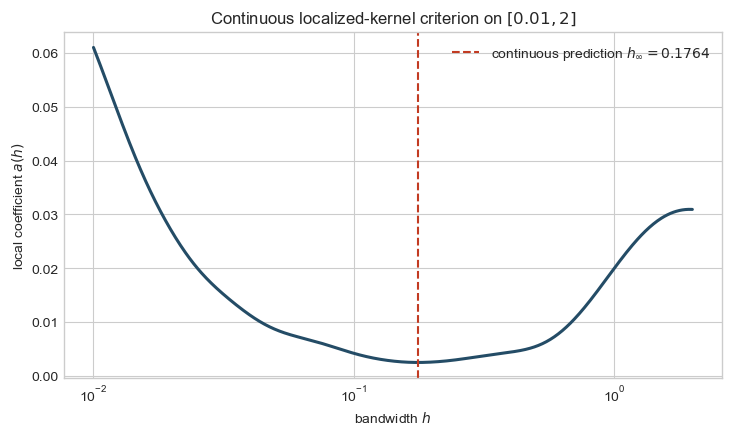

Continuous-limit prediction: h_infinity = 0.17642363


In [3]:
squared_differences = (
    samples[:, None] - samples[None, :]
) ** 2

def local_beta2_log_metric(
    bandwidth: float,
    squared_differences: np.ndarray,
) -> float:
    """Exact coefficient of (Delta log h)^2 for this KDE family."""
    h = float(bandwidth)
    q = 2.0 * h**2
    d = np.asarray(squared_differences, dtype=float)
    overlap = np.exp(-d / (2.0 * q)) / np.sqrt(2.0 * np.pi * q)
    second_q_factor = (
        3.0 / (4.0 * q**2)
        - 3.0 * d / (2.0 * q**3)
        + d**2 / (4.0 * q**4)
    )
    return float(
        2.0 * h**4 * np.mean(overlap * second_q_factor)
    )

continuous_minimum = minimize_scalar(
    lambda h: local_beta2_log_metric(
        h, squared_differences
    ),
    bounds=(H_MIN, H_MAX),
    method="bounded",
    options={"xatol": 1e-12},
)
if not continuous_minimum.success:
    raise RuntimeError(continuous_minimum.message)
h_infinity = float(continuous_minimum.x)
metric_grid = np.geomspace(H_MIN, H_MAX, 600)
metric_values = np.array([
    local_beta2_log_metric(h, squared_differences)
    for h in metric_grid
])

fig, ax = plt.subplots(figsize=(8.5, 4.5))                                                          ### PLOTTING
ax.plot(                                                                                            ### PLOTTING
    metric_grid, metric_values,                                                                     ### PLOTTING
    color="#244c66", linewidth=2.2                                                                  ### PLOTTING
)                                                                                                   ### PLOTTING
ax.axvline(                                                                                         ### PLOTTING
    h_infinity, color="#c23b22", linestyle="--",                                                    ### PLOTTING
    label=(                                                                                         ### PLOTTING
        rf"continuous prediction "                                                                  ### PLOTTING
        rf"$h_\infty={h_infinity:.4f}$"                                                             ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING
ax.set(                                                                                             ### PLOTTING
    xscale="log",                                                                                   ### PLOTTING
    xlabel=r"bandwidth $h$",                                                                        ### PLOTTING
    ylabel=r"local coefficient $a(h)$",                                                             ### PLOTTING
    title=(                                                                                         ### PLOTTING
        "Continuous localized-kernel criterion on "                                                 ### PLOTTING
        rf"$[{H_MIN:g},{H_MAX:g}]$"                                                                 ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING
ax.legend()                                                                                         ### PLOTTING
plt.show()                                                                                          ### PLOTTING
print(                                                                                              ### REPORTING
    "Continuous-limit prediction: "                                                                 ### REPORTING
    f"h_infinity = {h_infinity:.8f}"                                                                ### REPORTING
)                                                                                                   ### REPORTING


## Numerical method and validation

The project already contains an exact analytic beta-2 calculation. Its cost grows like $N^2n^2$, so the full sweep uses the existing Fourier reconstruction and one matrix product per $N$. The next cell checks that approximation against the exact helper on the smallest grid.

For numerical stability, the Perron vector is computed from the off-diagonal part $A_N=S_N-I_N$. Adding the identity does not change the eigenvectors. Before the centralized Lanczos solve, all off-diagonal entries are multiplied by the same factor so that the largest equals one; this also leaves the eigenvectors unchanged and prevents the $\alpha=3$ regime from becoming numerically indistinguishable from the identity.

In [4]:
validation_grid = bandwidth_grid_linear_in_psi_beta(
    h_min=H_MIN, h_max=H_MAX, beta=BETA, grid_size=25
)
validation_exact = beta2_divergence_matrix(
    samples, validation_grid
)
validation_fft = beta2_divergence_matrix_fft(
    samples, validation_grid,
    half_width=FFT_HALF_WIDTH,
    spatial_points=FFT_SPATIAL_POINTS,
)
validation_abs_error = np.max(
    np.abs(validation_fft - validation_exact)
)
validation_rel_error = (
    validation_abs_error / np.max(validation_exact)
)

print(f"maximum absolute D2 error: {validation_abs_error:.3e}")                                     ### REPORTING
print(f"error relative to max(D2): {validation_rel_error:.3e}")                                     ### REPORTING
if validation_rel_error > 2e-5:
    warnings.warn(
        "Increase FFT_HALF_WIDTH or FFT_SPATIAL_POINTS."
    )

maximum absolute D2 error: 2.170e-14
error relative to max(D2): 1.960e-13


In [5]:
LAMBDA_RULES = {
    r"$N^{1/2}$ (admissible)": lambda N: N**0.5,
    r"$N$ (admissible)": lambda N: float(N),
    r"$N^{3/2}$ (admissible)": lambda N: N**1.5,
    r"$1$ (not localized)": lambda N: 1.0,
    r"$N^2$ (mesh-scale)": lambda N: float(N**2),
    r"$N^3$ (collapse)": lambda N: float(N**3),
}
REGIME_ORDER = list(LAMBDA_RULES)
REGIME_COLORS = dict(zip(
    REGIME_ORDER,
    ["#0072B2", "#009E73", "#CC79A7",
     "#E69F00", "#7A7A7A", "#D55E00"],
))

rows = []
largest_grid_vectors = {}
start_time = time.perf_counter()

for N in N_VALUES:
    N = int(N)
    h_grid = bandwidth_grid_linear_in_psi_beta(
        h_min=H_MIN, h_max=H_MAX,
        beta=BETA, grid_size=N,
    )
    divergence = beta2_divergence_matrix_fft(
        samples, h_grid,
        half_width=FFT_HALF_WIDTH,
        spatial_points=FFT_SPATIAL_POINTS,
    )
    reference_index = nearest_bandwidth_grid_index(
        h_infinity, h_grid
    )
    neighbor_left = min(reference_index, N - 2)
    neighbor_D = divergence[
        neighbor_left, neighbor_left + 1
    ]
    endpoint_D = divergence[0, -1]

    for regime, lambda_rule in LAMBDA_RULES.items():
        lambda_value = float(lambda_rule(N))
        vector = perron_vector_from_divergence(
            divergence, lambda_value
        )
        selected_index = int(perron_peak_index(vector))
        selected_h = float(h_grid[selected_index])

        rows.append({
            "N": N,
            "regime": regime,
            "lambda": lambda_value,
            "lambda_over_N2": lambda_value / N**2,
            "selected_index": selected_index,
            "selected_h": selected_h,
            "absolute_error": abs(selected_h - h_infinity),
            "global_exponent": lambda_value * endpoint_D,
            "neighbor_exponent": lambda_value * neighbor_D,
            "neighbor_similarity": np.exp(
                -lambda_value * neighbor_D
            ),
        })
        if N == int(N_VALUES[-1]):
            largest_grid_vectors[regime] = (
                h_grid.copy(),
                vector.copy(),
            )

results = pd.DataFrame(rows)
results["regime"] = pd.Categorical(
    results["regime"],
    categories=REGIME_ORDER,
    ordered=True,
)
results = results.sort_values(
    ["regime", "N"]
).reset_index(drop=True)

elapsed = time.perf_counter() - start_time
print(                                                                                              ### REPORTING
    f"Completed {len(results)} selector computations "                                              ### REPORTING
    f"in {elapsed:.2f} seconds."                                                                    ### REPORTING
)                                                                                                   ### REPORTING
display(results.pivot(                                                                              ### REPORTING
    index="N", columns="regime", values="selected_h"                                                ### REPORTING
).round(6))                                                                                         ### REPORTING


Completed 180 selector computations in 681.35 seconds.


regime,$N^{1/2}$ (admissible),$N$ (admissible),$N^{3/2}$ (admissible),$1$ (not localized),$N^2$ (mesh-scale),$N^3$ (collapse)
N,,,,,,
100,0.099871,0.200259,0.189824,0.085057,0.179932,0.179932
200,0.104122,0.197266,0.182122,0.086417,0.177337,0.177337
300,0.111333,0.192837,0.179642,0.086872,0.176487,0.176487
400,0.203755,0.193214,0.178417,0.087100,0.176064,0.176064
500,0.201833,0.191398,0.179585,0.087237,0.177688,0.175811
600,0.202346,0.190197,0.178778,0.087328,0.177203,0.177203
700,0.201181,0.189345,0.178204,0.087394,0.176858,0.176858
800,0.201646,0.188708,0.177775,0.087443,0.176600,0.176600
900,0.200820,0.188214,0.178491,0.087481,0.176400,0.176400


In [6]:
plot_ticks = np.array([
    100, 500, 1000, 1500, 2000, 2500, 3000,
])

def plot_selected_bandwidth_paths(
    *, show_continuous_reference: bool,
) -> None:
    fig, ax = plt.subplots(figsize=(9.5, 5.8))                                                      ### PLOTTING
    for regime in REGIME_ORDER:
        subset = results[results["regime"] == regime]
        admissible = "admissible" in regime
        ax.plot(                                                                                    ### PLOTTING
            subset["N"], subset["selected_h"],                                                      ### PLOTTING
            marker="o",                                                                             ### PLOTTING
            linewidth=2.2 if admissible else 1.6,                                                   ### PLOTTING
            linestyle="-" if admissible else "--",                                                  ### PLOTTING
            color=REGIME_COLORS[regime],                                                            ### PLOTTING
            label=regime,                                                                           ### PLOTTING
        )                                                                                           ### PLOTTING
    if show_continuous_reference:                                                                   ### PLOTTING
        ax.axhline(                                                                                 ### PLOTTING
            h_infinity, color="black",                                                              ### PLOTTING
            linestyle=":", linewidth=2.2,                                                           ### PLOTTING
            label=(                                                                                 ### PLOTTING
                rf"continuous $h_\infty="                                                           ### PLOTTING
                rf"{h_infinity:.4f}$"                                                               ### PLOTTING
            ),                                                                                      ### PLOTTING
        )                                                                                           ### PLOTTING
    ax.set(                                                                                         ### PLOTTING
        xlabel=r"number of bandwidths $N$",                                                         ### PLOTTING
        ylabel=r"selected bandwidth $h_{\mathrm{spec},N}$",                                         ### PLOTTING
        title=(                                                                                     ### PLOTTING
            "Finite selector versus continuous reference"                                           ### PLOTTING
            if show_continuous_reference                                                            ### PLOTTING
            else "Selected bandwidth across grid resolutions"                                       ### PLOTTING
        ),                                                                                          ### PLOTTING
    )                                                                                               ### PLOTTING
    ax.set_xticks(plot_ticks, labels=plot_ticks)                                                    ### PLOTTING
    ax.legend(ncol=2, frameon=True)                                                                 ### PLOTTING
    fig.tight_layout()                                                                              ### PLOTTING
    plt.show()                                                                                      ### PLOTTING

Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/experiment_1_joint_n_lambda_limit/002_selected_bandwidth_across_grid_resolutions.pdf


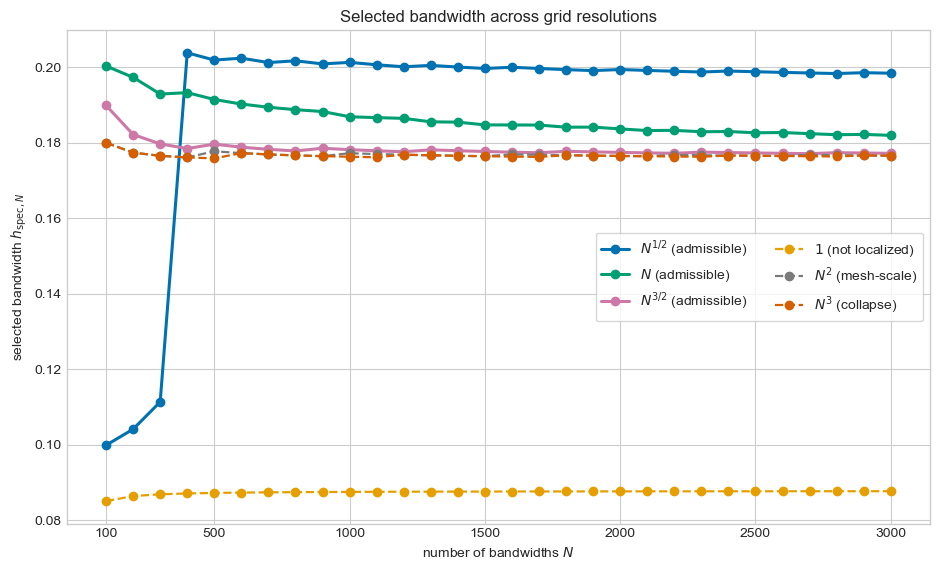

In [7]:
plot_selected_bandwidth_paths(                                                                      ### PLOTTING
    show_continuous_reference=False,                                                                ### PLOTTING
)                                                                                                   ### PLOTTING

Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/experiment_1_joint_n_lambda_limit/003_finite_selector_versus_continuous_reference.pdf


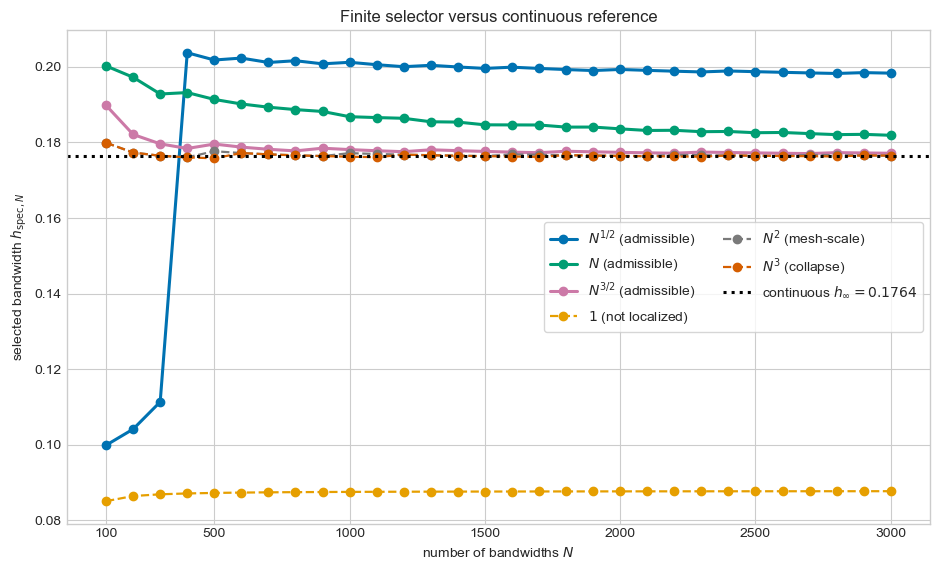

In [8]:
plot_selected_bandwidth_paths(                                                                      ### PLOTTING
    show_continuous_reference=True,                                                                 ### PLOTTING
)                                                                                                   ### PLOTTING

In [9]:
CUSTOM_ALPHA_VALUES = np.round(
    np.arange(1.0, 3.0 + 0.05, 0.5),
    1,
)
CUSTOM_ALPHA_VALUES                                                                                 ### REPORTING

array([1. , 1.5, 2. , 2.5, 3. ])

## Joint $(N,\lambda_N)$ limit for a user-selected $\beta$

This repeats Figure 3.6 with a freely chosen value of $\beta$. Here $\beta$ determines the coordinate $\psi_\beta$ in which the bandwidth grid is equidistant, and hence the local criterion $\widehat Q_{n,\beta}(h)=h^\beta\lVert\partial_h\widehat f_h\rVert_2^2$. The similarity still uses the same $L^2$ divergence as the original experiment. Change only `CUSTOM_BETA` in the first line of the next cell.

In [10]:
CUSTOM_BETA = 1/7  # Choose beta here.

if not np.isfinite(CUSTOM_BETA) or CUSTOM_BETA <= 0.0:
    raise ValueError("CUSTOM_BETA must be positive and finite.")

CUSTOM_BETA_N_VALUES = N_VALUES.copy()
# All alpha values from 1.0 to 3.0 in steps of 0.1
CUSTOM_ALPHA_VALUES = np.round(
    np.arange(1.0, 3.0 + 0.05, 0.5),
    1,
)

CUSTOM_BETA_LAMBDA_RULES = {
    r"$N^{0.5}$": lambda N: N**0.5,
}

for alpha in CUSTOM_ALPHA_VALUES:

    if np.isclose(alpha, 2.0):
        label = r"$N^{2.0}$ (mesh-scale)"
    elif alpha > 2.0:
        label = rf"$N^{{{alpha:.1f}}}$ (collapse)"
    else:
        label = rf"$N^{{{alpha:.1f}}}$"

    # alpha=alpha is important so that each lambda keeps
    # its own exponent rather than the final loop value.
    CUSTOM_BETA_LAMBDA_RULES[label] = (
        lambda N, alpha=alpha: N**alpha
    )

CUSTOM_BETA_LAMBDA_RULES[
    r"$1$ (not localized)"
] = lambda N: 1.0


CUSTOM_BETA_REGIME_ORDER = list(
    CUSTOM_BETA_LAMBDA_RULES
)


# Generate enough distinct colors automatically
cmap = plt.colormaps["turbo"]

CUSTOM_BETA_REGIME_COLORS = {
    regime: cmap(i / (len(CUSTOM_BETA_REGIME_ORDER) - 1))
    for i, regime in enumerate(CUSTOM_BETA_REGIME_ORDER)
}


def local_custom_beta_metric(
    bandwidth: float,
    squared_differences: np.ndarray,
) -> float:
    """Coefficient of (Delta psi_beta)^2 for this sample."""
    h = float(bandwidth)
    return float(
        h ** (CUSTOM_BETA - 2.0)
        * local_beta2_log_metric(h, squared_differences)
    )


custom_beta_continuous_minimum = minimize_scalar(
    lambda h: local_custom_beta_metric(h, squared_differences),
    bounds=(H_MIN, H_MAX),
    method="bounded",
    options={"xatol": 1e-12},
)
if not custom_beta_continuous_minimum.success:
    raise RuntimeError(custom_beta_continuous_minimum.message)

# Include the endpoints because, for some beta, the minimum lies
# on the boundary of the permitted bandwidth interval.
custom_beta_reference_candidates = np.array([
    H_MIN,
    float(custom_beta_continuous_minimum.x),
    H_MAX,
])
custom_beta_reference_values = np.array([
    local_custom_beta_metric(h, squared_differences)
    for h in custom_beta_reference_candidates
])
custom_beta_h_infinity = float(
    custom_beta_reference_candidates[
        np.argmin(custom_beta_reference_values)
    ]
)

custom_beta_rows = []
custom_beta_start_time = time.perf_counter()

for current_N in CUSTOM_BETA_N_VALUES:
    current_N = int(current_N)
    current_h_grid = bandwidth_grid_linear_in_psi_beta(
        h_min=H_MIN,
        h_max=H_MAX,
        beta=CUSTOM_BETA,
        grid_size=current_N,
    )
    # Beta changes the bandwidth coordinate/grid. The divergence
    # remains the same L2 divergence used in Figure 3.6.
    current_divergence = beta2_divergence_matrix_fft(
        samples,
        current_h_grid,
        half_width=FFT_HALF_WIDTH,
        spatial_points=FFT_SPATIAL_POINTS,
    )

    for regime, lambda_rule in CUSTOM_BETA_LAMBDA_RULES.items():
        lambda_value = float(lambda_rule(current_N))
        current_vector = perron_vector_from_divergence(
            current_divergence, lambda_value
        )
        selected_index = int(perron_peak_index(current_vector))
        custom_beta_rows.append({
            "beta": CUSTOM_BETA,
            "N": current_N,
            "regime": regime,
            "lambda": lambda_value,
            "selected_index": selected_index,
            "selected_h": float(current_h_grid[selected_index]),
            "continuous_reference": custom_beta_h_infinity,
        })

custom_beta_results = pd.DataFrame(custom_beta_rows)
custom_beta_results["regime"] = pd.Categorical(
    custom_beta_results["regime"],
    categories=CUSTOM_BETA_REGIME_ORDER,
    ordered=True,
)
custom_beta_results = custom_beta_results.sort_values(
    ["regime", "N"]
).reset_index(drop=True)

custom_beta_elapsed = time.perf_counter() - custom_beta_start_time
print(                                                                                              ### REPORTING
    f"Completed beta={CUSTOM_BETA:g} joint-limit sweep "                                            ### REPORTING
    f"in {custom_beta_elapsed:.2f} seconds."                                                        ### REPORTING
)                                                                                                   ### REPORTING
print(                                                                                              ### REPORTING
    "Continuous reference for this beta: "                                                          ### REPORTING
    f"h_infinity = {custom_beta_h_infinity:.8f}"                                                    ### REPORTING
)                                                                                                   ### REPORTING
display(custom_beta_results.pivot(                                                                  ### REPORTING
    index="N",                                                                                      ### REPORTING
    columns="regime",                                                                               ### REPORTING
    values="selected_h",                                                                            ### REPORTING
).round(6))                                                                                         ### REPORTING

Completed beta=0.142857 joint-limit sweep in 874.94 seconds.
Continuous reference for this beta: h_infinity = 2.00000000


regime,$N^{0.5}$,$N^{1.0}$,$N^{1.5}$,$N^{2.0}$ (mesh-scale),$N^{2.5}$ (collapse),$N^{3.0}$ (collapse),$1$ (not localized)
N,,,,,,,
100,0.965781,1.068672,1.571616,1.806319,1.913746,1.956839,0.965781
200,0.970830,1.197055,1.690231,1.871370,1.946330,1.978520,0.960630
300,0.979296,1.309029,1.743797,1.900069,1.964268,1.985702,0.958925
400,0.978427,1.380786,1.775870,1.914394,1.967866,1.989285,0.958075
500,0.981979,1.432278,1.799360,1.927254,1.974303,1.991432,0.957566
600,0.984345,1.473635,1.815019,1.932263,1.978591,1.992862,0.957226
700,0.986035,1.503209,1.829243,1.938891,1.981653,1.993883,0.956984
800,0.987301,1.525408,1.837251,1.943861,1.981274,1.994649,0.956802
900,0.990548,1.545020,1.845845,1.947726,1.983357,1.995244,0.956661


In [ ]:
custom_beta_plot_ticks = np.array([
    100, 500, 1000, 1500, 2000, 2500, 3000,
])

fig, ax = plt.subplots(figsize=(9.5, 5.8))                                                          ### PLOTTING
for regime in CUSTOM_BETA_REGIME_ORDER:
    subset = custom_beta_results[
        custom_beta_results["regime"] == regime
    ]
    admissible = "admissible" in regime
    ax.plot(                                                                                        ### PLOTTING
        subset["N"],                                                                                ### PLOTTING
        subset["selected_h"],                                                                       ### PLOTTING
        marker="o",                                                                                 ### PLOTTING
        linewidth=2.2 if admissible else 1.6,                                                       ### PLOTTING
        linestyle="-" if admissible else "--",                                                      ### PLOTTING
        color=CUSTOM_BETA_REGIME_COLORS[regime],                                                    ### PLOTTING
        label=regime,                                                                               ### PLOTTING
    )                                                                                               ### PLOTTING

ax.axhline(                                                                                         ### PLOTTING
    custom_beta_h_infinity,                                                                         ### PLOTTING
    color="black",                                                                                  ### PLOTTING
    linestyle=":",                                                                                  ### PLOTTING
    linewidth=2.2,                                                                                  ### PLOTTING
    label=(                                                                                         ### PLOTTING
        rf"continuous $h_\infty="                                                                   ### PLOTTING
        rf"{custom_beta_h_infinity:.4f}$"                                                           ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING
ax.set(                                                                                             ### PLOTTING
    xlabel=r"number of bandwidths $N$",                                                             ### PLOTTING
    ylabel=r"selected bandwidth $h_{\mathrm{spec},N}$",                                             ### PLOTTING
    title=(                                                                                         ### PLOTTING
        "Joint grid-localization limit "                                                            ### PLOTTING
        rf"for $\beta={CUSTOM_BETA:g}$"                                                             ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING
ax.set_xticks(                                                                                      ### PLOTTING
    custom_beta_plot_ticks,                                                                         ### PLOTTING
    labels=custom_beta_plot_ticks,                                                                  ### PLOTTING
)                                                                                                   ### PLOTTING
ax.legend(ncol=2, frameon=True)                                                                     ### PLOTTING
fig.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING

In [ ]:
# ============================================================
# MONTE CARLO DISTRIBUTION OF THE SELECTED BANDWIDTH
#
# beta = 1/7
# N = 1000
# lambda_N = N^1.9
# sample size n = 200
# Monte Carlo repetitions = 200
# ============================================================

MC_BETA = 1 / 7
MC_N = 1000
MC_ALPHA = 1.9
MC_LAMBDA = float(MC_N ** MC_ALPHA)

MC_SAMPLE_SIZE = 200
MC_REPETITIONS = 2000
MC_SEED = 12345


# ============================================================
# SAMPLE GENERATOR
#
# IMPORTANT:
# Replace this by the distribution f used in your experiment.
#
# Example below: standard normal distribution.
# ============================================================

def draw_sample(rng, n):
    return rng.normal(
        loc=0.0,
        scale=1.0,
        size=n,
    )


# ============================================================
# Fixed bandwidth grid
#
# This is identical for every Monte Carlo repetition.
# ============================================================

mc_h_grid = bandwidth_grid_linear_in_psi_beta(
    h_min=H_MIN,
    h_max=H_MAX,
    beta=MC_BETA,
    grid_size=MC_N,
)


# ============================================================
# Monte Carlo simulation
# ============================================================

rng = np.random.default_rng(MC_SEED)

mc_rows = []

mc_start_time = time.perf_counter()


for repetition in range(1, MC_REPETITIONS + 1):

    # --------------------------------------------------------
    # Draw new independent sample X_1^(i), ..., X_n^(i)
    # --------------------------------------------------------

    current_samples = draw_sample(
        rng,
        MC_SAMPLE_SIZE,
    )


    # --------------------------------------------------------
    # Compute divergence matrix for this sample
    # --------------------------------------------------------

    current_divergence = beta2_divergence_matrix_fft(
        current_samples,
        mc_h_grid,
        half_width=FFT_HALF_WIDTH,
        spatial_points=FFT_SPATIAL_POINTS,
    )


    # --------------------------------------------------------
    # Perron vector
    # --------------------------------------------------------

    current_vector = perron_vector_from_divergence(
        current_divergence,
        MC_LAMBDA,
    )


    # --------------------------------------------------------
    # Selected bandwidth
    # --------------------------------------------------------

    selected_index = int(
        perron_peak_index(current_vector)
    )

    selected_h = float(
        mc_h_grid[selected_index]
    )


    mc_rows.append({
        "repetition": repetition,
        "n": MC_SAMPLE_SIZE,
        "N": MC_N,
        "beta": MC_BETA,
        "alpha": MC_ALPHA,
        "lambda": MC_LAMBDA,
        "selected_index": selected_index,
        "selected_h": selected_h,
    })


    # --------------------------------------------------------
    # Progress output
    # --------------------------------------------------------

    if repetition % 10 == 0:

        elapsed = (
            time.perf_counter()
            - mc_start_time
        )

        print(                                                                                      ### REPORTING
            f"Completed {repetition:3d}/"                                                           ### REPORTING
            f"{MC_REPETITIONS} repetitions "                                                        ### REPORTING
            f"after {elapsed:.1f} seconds."                                                         ### REPORTING
        )                                                                                           ### REPORTING


# ============================================================
# Results
# ============================================================

mc_bandwidth_results = pd.DataFrame(
    mc_rows
)

mc_elapsed = (
    time.perf_counter()
    - mc_start_time
)

print()                                                                                             ### REPORTING
print(                                                                                              ### REPORTING
    f"Completed all {MC_REPETITIONS} repetitions "                                                  ### REPORTING
    f"in {mc_elapsed:.2f} seconds."                                                                 ### REPORTING
)                                                                                                   ### REPORTING

print(                                                                                              ### REPORTING
    f"beta     = {MC_BETA:.8f}"                                                                     ### REPORTING
)                                                                                                   ### REPORTING

print(                                                                                              ### REPORTING
    f"N        = {MC_N}"                                                                            ### REPORTING
)                                                                                                   ### REPORTING

print(                                                                                              ### REPORTING
    f"alpha    = {MC_ALPHA}"                                                                        ### REPORTING
)                                                                                                   ### REPORTING

print(                                                                                              ### REPORTING
    f"lambda_N = {MC_LAMBDA:.6e}"                                                                   ### REPORTING
)                                                                                                   ### REPORTING


# ============================================================
# Summary statistics
# ============================================================

selected_bandwidths = (
    mc_bandwidth_results[
        "selected_h"
    ].to_numpy()
)


mc_mean = float(
    np.mean(selected_bandwidths)
)

mc_median = float(
    np.median(selected_bandwidths)
)

mc_std = float(
    np.std(
        selected_bandwidths,
        ddof=1,
    )
)

mc_q025, mc_q25, mc_q75, mc_q975 = (
    np.quantile(
        selected_bandwidths,
        [0.025, 0.25, 0.75, 0.975],
    )
)


print()                                                                                             ### REPORTING
print("Selected bandwidth distribution")                                                            ### REPORTING
print("--------------------------------")                                                           ### REPORTING
print(                                                                                              ### REPORTING
    f"mean       = {mc_mean:.8f}"                                                                   ### REPORTING
)                                                                                                   ### REPORTING
print(                                                                                              ### REPORTING
    f"median     = {mc_median:.8f}"                                                                 ### REPORTING
)                                                                                                   ### REPORTING
print(                                                                                              ### REPORTING
    f"std        = {mc_std:.8f}"                                                                    ### REPORTING
)                                                                                                   ### REPORTING
print(                                                                                              ### REPORTING
    f"2.5%       = {mc_q025:.8f}"                                                                   ### REPORTING
)                                                                                                   ### REPORTING
print(                                                                                              ### REPORTING
    f"25%        = {mc_q25:.8f}"                                                                    ### REPORTING
)                                                                                                   ### REPORTING
print(                                                                                              ### REPORTING
    f"75%        = {mc_q75:.8f}"                                                                    ### REPORTING
)                                                                                                   ### REPORTING
print(                                                                                              ### REPORTING
    f"97.5%      = {mc_q975:.8f}"                                                                   ### REPORTING
)                                                                                                   ### REPORTING


display(                                                                                            ### REPORTING
    mc_bandwidth_results                                                                            ### REPORTING
)                                                                                                   ### REPORTING


# ============================================================
# HISTOGRAM OF SELECTED BANDWIDTHS
# ============================================================

fig, ax = plt.subplots(                                                                             ### PLOTTING
    figsize=(10, 6)                                                                                 ### PLOTTING
)                                                                                                   ### PLOTTING

ax.hist(                                                                                            ### PLOTTING
    selected_bandwidths,                                                                            ### PLOTTING
    bins=20,                                                                                        ### PLOTTING
    density=True,                                                                                   ### PLOTTING
    alpha=0.75,                                                                                     ### PLOTTING
    edgecolor="black",                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING


# Mean
ax.axvline(                                                                                         ### PLOTTING
    mc_mean,                                                                                        ### PLOTTING
    linestyle="--",                                                                                 ### PLOTTING
    linewidth=1.8,                                                                                  ### PLOTTING
    label=rf"mean $={mc_mean:.4f}$",                                                                ### PLOTTING
)                                                                                                   ### PLOTTING


# Median
ax.axvline(                                                                                         ### PLOTTING
    mc_median,                                                                                      ### PLOTTING
    linestyle=":",                                                                                  ### PLOTTING
    linewidth=1.8,                                                                                  ### PLOTTING
    label=rf"median $={mc_median:.4f}$",                                                            ### PLOTTING
)                                                                                                   ### PLOTTING


ax.set_xlabel(                                                                                      ### PLOTTING
    r"selected bandwidth $\hat h_{\rm spec}$"                                                       ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_ylabel(                                                                                      ### PLOTTING
    "density"                                                                                       ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_title(
    rf"Monte Carlo distribution of "
    rf"$\hat h_{{\rm spec}}$"
    "\n"
    rf"$n={MC_SAMPLE_SIZE}$, "
    rf"$N={MC_N}$, "
    rf"$\beta=1/7$, "
    rf"$\lambda_N=N^{{{MC_ALPHA}}}$"
)

ax.grid(                                                                                            ### PLOTTING
    alpha=0.25                                                                                      ### PLOTTING
)                                                                                                   ### PLOTTING

ax.legend()                                                                                         ### PLOTTING

plt.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING


# ============================================================
# EMPIRICAL CDF
# ============================================================

sorted_h = np.sort(
    selected_bandwidths
)

empirical_cdf = (
    np.arange(
        1,
        MC_REPETITIONS + 1,
    )
    / MC_REPETITIONS
)


fig, ax = plt.subplots(                                                                             ### PLOTTING
    figsize=(10, 6)                                                                                 ### PLOTTING
)                                                                                                   ### PLOTTING

ax.step(                                                                                            ### PLOTTING
    sorted_h,                                                                                       ### PLOTTING
    empirical_cdf,                                                                                  ### PLOTTING
    where="post",                                                                                   ### PLOTTING
    linewidth=1.8,                                                                                  ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_xlabel(                                                                                      ### PLOTTING
    r"selected bandwidth $\hat h_{\rm spec}$"                                                       ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_ylabel(                                                                                      ### PLOTTING
    "empirical CDF"                                                                                 ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_title(
    rf"Empirical distribution of "
    rf"$\hat h_{{\rm spec}}$, "
    rf"$n={MC_SAMPLE_SIZE}$"
)

ax.grid(                                                                                            ### PLOTTING
    alpha=0.25                                                                                      ### PLOTTING
)                                                                                                   ### PLOTTING

plt.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING

In [ ]:
# ============================================================
# DISCRETE DISTRIBUTION OF SELECTED BANDWIDTHS
#
# plot_bandwidth_distributions expects one count/weight for
# every candidate bandwidth in mc_h_grid.
# ============================================================

selected_indices = (
    mc_bandwidth_results["selected_index"]
    .to_numpy(dtype=int)
)

# Count how often each bandwidth-grid point was selected.
selected_counts = np.bincount(
    selected_indices,
    minlength=len(mc_h_grid),
).astype(float)


# ============================================================
# Optional reference lines
#
# The plotting function expects GRID INDICES, not bandwidth
# values, for the reference lines.
# ============================================================

mean_index = int(
    np.argmin(
        np.abs(mc_h_grid - mc_mean)
    )
)

median_index = int(
    np.argmin(
        np.abs(mc_h_grid - mc_median)
    )
)


reference_lines = [
    (
        rf"mean $\hat h_{{\rm spec}}={mc_mean:.4f}$",
        mean_index,
        "#D55E00",
    ),
    (
        rf"median $\hat h_{{\rm spec}}={mc_median:.4f}$",
        median_index,
        "#009E73",
    ),
]


# ============================================================
# Plot
# ============================================================

fig = plot_bandwidth_distributions(                                                                 ### PLOTTING
    h_grid=mc_h_grid,                                                                               ### PLOTTING
    distributions={                                                                                 ### PLOTTING
        rf"$\beta=1/7,\ N={MC_N},\ "                                                                ### PLOTTING
        rf"\lambda_N=N^{{{MC_ALPHA}}}$":                                                            ### PLOTTING
            selected_counts,                                                                        ### PLOTTING
    },                                                                                              ### PLOTTING
    reference_lines=reference_lines,                                                                ### PLOTTING
    tick_count=9,                                                                                   ### PLOTTING
    width=1100,                                                                                     ### PLOTTING
    height=600,                                                                                     ### PLOTTING
)                                                                                                   ### PLOTTING

fig.update_layout(                                                                                  ### PLOTTING
    title=(                                                                                         ### PLOTTING
        rf"Distribution of selected bandwidths "                                                    ### PLOTTING
        rf"over {MC_REPETITIONS} samples"                                                           ### PLOTTING
        "<br>"                                                                                      ### PLOTTING
        rf"<sup>$n={MC_SAMPLE_SIZE}$, "                                                             ### PLOTTING
        rf"$N={MC_N}$, "                                                                            ### PLOTTING
        rf"$\beta=1/7$, "                                                                           ### PLOTTING
        rf"$\lambda_N=N^{{{MC_ALPHA}}}$</sup>"                                                      ### PLOTTING
    )                                                                                               ### PLOTTING
)                                                                                                   ### PLOTTING

fig.show()                                                                                          ### PLOTTING

In [ ]:
MESH_STRESS_N = 400
MESH_TARGET_H = 0.70
MESH_ALPHA_VALUES = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 3.0])
MESH_ALPHA_COLORS = plt.colormaps["tab20"](
    np.arange(len(MESH_ALPHA_VALUES))
)
MESH_GAP_FRACTIONS = np.array([
    1.00, 0.90, 0.75, 0.60, 0.50, 0.40,
    0.35, 0.30, 0.25, 0.20, 0.15, 0.10,
])

mesh_base_grid = bandwidth_grid_linear_in_psi_beta(
    H_MIN,
    H_MAX,
    beta=BETA,
    grid_size=MESH_STRESS_N,
)
mesh_base_psi = np.log(mesh_base_grid)
mesh_delta_psi = (
    mesh_base_psi[1] - mesh_base_psi[0]
)
mesh_close_pair_left = int(
    np.argmin(
        np.abs(mesh_base_grid - MESH_TARGET_H)
    )
)
mesh_close_pair_left = min(
    mesh_close_pair_left,
    MESH_STRESS_N - 2,
)

mesh_rows = []
mesh_alpha3_profiles = {}

for gap_fraction in MESH_GAP_FRACTIONS:
    perturbed_psi = mesh_base_psi.copy()
    perturbed_psi[mesh_close_pair_left + 1] = (
        perturbed_psi[mesh_close_pair_left]
        + gap_fraction * mesh_delta_psi
    )
    h_grid = np.exp(perturbed_psi)
    divergence = beta2_divergence_matrix_fft(
        samples,
        h_grid,
        half_width=FFT_HALF_WIDTH,
        spatial_points=FFT_SPATIAL_POINTS,
    )

    for alpha in MESH_ALPHA_VALUES:
        alpha = float(alpha)
        lambda_value = float(
            MESH_STRESS_N ** alpha
        )
        vector = perron_vector_from_divergence(
            divergence, lambda_value
        )
        selected_index = int(perron_peak_index(vector))

        mesh_rows.append({
            "gap_fraction": gap_fraction,
            "alpha": alpha,
            "lambda": lambda_value,
            "selected_h": float(h_grid[selected_index]),
            "selected_index": selected_index,
            "close_pair_h_left": float(
                h_grid[mesh_close_pair_left]
            ),
            "close_pair_h_right": float(
                h_grid[mesh_close_pair_left + 1]
            ),
            "close_pair_similarity": float(np.exp(
                -lambda_value * divergence[
                    mesh_close_pair_left,
                    mesh_close_pair_left + 1,
                ]
            )),
        })
        if (
            np.isclose(alpha, 3.0)
            and gap_fraction in {1.0, 0.2}
        ):
            mesh_alpha3_profiles[gap_fraction] = (
                h_grid.copy(),
                vector.copy(),
            )

mesh_stress_results = pd.DataFrame(mesh_rows)
mesh_selected_table = mesh_stress_results.pivot(
    index="gap_fraction",
    columns="alpha",
    values="selected_h",
)
print(                                                                                              ### REPORTING
    f"Completed {len(mesh_stress_results)} mesh-stress "                                            ### REPORTING
    "selector computations."                                                                        ### REPORTING
)                                                                                                   ### REPORTING
display(                                                                                            ### REPORTING
    mesh_selected_table.loc[                                                                        ### REPORTING
        [1.0, 0.6, 0.4, 0.3, 0.2, 0.1]                                                              ### REPORTING
    ].round(6)                                                                                      ### REPORTING
)                                                                                                   ### REPORTING


In [ ]:
CUSTOM_BETA = 1/7  # Choose beta here.

if not np.isfinite(CUSTOM_BETA) or CUSTOM_BETA <= 0.0:
    raise ValueError("CUSTOM_BETA must be positive and finite.")

CUSTOM_BETA_N_VALUES = N_VALUES.copy()

# All exponents alpha = 1.0, 1.1, ..., 3.0
CUSTOM_ALPHA_VALUES = np.round(
    np.arange(1.0, 3.01, 0.5),
    1,
)

CUSTOM_BETA_LAMBDA_RULES = {
    r"$N^{0.5}$": lambda N: N**0.5,
}

for alpha in CUSTOM_ALPHA_VALUES:
    if np.isclose(alpha, 2.0):
        label = r"$N^{2.0}$ (mesh-scale)"
    elif alpha > 2.0:
        label = rf"$N^{{{alpha:.1f}}}$ (collapse)"
    else:
        label = rf"$N^{{{alpha:.1f}}}$"

    CUSTOM_BETA_LAMBDA_RULES[label] = (
        lambda N, alpha=alpha: N**alpha
    )

CUSTOM_BETA_LAMBDA_RULES[
    r"$1$ (not localized)"
] = lambda N: 1.0


CUSTOM_BETA_REGIME_ORDER = list(
    CUSTOM_BETA_LAMBDA_RULES
)


# Automatically assign a different color to every curve
cmap = plt.colormaps["turbo"]

CUSTOM_BETA_REGIME_COLORS = {
    regime: cmap(i / (len(CUSTOM_BETA_REGIME_ORDER) - 1))
    for i, regime in enumerate(CUSTOM_BETA_REGIME_ORDER)
}


def psi_beta(h: float, beta: float) -> float:
    """Bandwidth coordinate psi_beta with psi_beta'(h)=h^{-beta/2}."""
    h = float(h)

    if np.isclose(beta, 2.0):
        return np.log(h)

    return h ** (1.0 - beta / 2.0) / (1.0 - beta / 2.0)


def local_custom_beta_metric(
    bandwidth: float,
    squared_differences: np.ndarray,
) -> float:
    """Coefficient of (Delta psi_beta)^2 for this sample."""
    h = float(bandwidth)
    return float(
        h ** (CUSTOM_BETA - 2.0)
        * local_beta2_log_metric(h, squared_differences)
    )


# ------------------------------------------------------------
# Continuous reference
# ------------------------------------------------------------

custom_beta_continuous_minimum = minimize_scalar(
    lambda h: local_custom_beta_metric(h, squared_differences),
    bounds=(H_MIN, H_MAX),
    method="bounded",
    options={"xatol": 1e-12},
)

if not custom_beta_continuous_minimum.success:
    raise RuntimeError(custom_beta_continuous_minimum.message)

custom_beta_reference_candidates = np.array([
    H_MIN,
    float(custom_beta_continuous_minimum.x),
    H_MAX,
])

custom_beta_reference_values = np.array([
    local_custom_beta_metric(h, squared_differences)
    for h in custom_beta_reference_candidates
])

custom_beta_h_infinity = float(
    custom_beta_reference_candidates[
        np.argmin(custom_beta_reference_values)
    ]
)


# ------------------------------------------------------------
# Diagnostic experiment
#
# We study directly
#
#   Delta_psi sum_j S_ij
#
# versus
#
#   integral exp(-lambda Q_i delta^2) ddelta
#       = sqrt(pi / (lambda Q_i)).
#
# The quantity
#
#   sqrt(lambda Q_i) Delta_psi
#
# measures mesh spacing relative to localization width.
# ------------------------------------------------------------

diagnostic_rows = []
diagnostic_start_time = time.perf_counter()

psi_min = psi_beta(H_MIN, CUSTOM_BETA)
psi_max = psi_beta(H_MAX, CUSTOM_BETA)

for current_N in CUSTOM_BETA_N_VALUES:

    current_N = int(current_N)

    current_h_grid = bandwidth_grid_linear_in_psi_beta(
        h_min=H_MIN,
        h_max=H_MAX,
        beta=CUSTOM_BETA,
        grid_size=current_N,
    )

    delta_psi = (psi_max - psi_min) / (current_N - 1)

    current_divergence = beta2_divergence_matrix_fft(
        samples,
        current_h_grid,
        half_width=FFT_HALF_WIDTH,
        spatial_points=FFT_SPATIAL_POINTS,
    )

    # Use the grid point closest to the continuous limiting minimizer.
    reference_index = int(
        np.argmin(
            np.abs(current_h_grid - custom_beta_h_infinity)
        )
    )

    reference_h = float(current_h_grid[reference_index])

    Q_i = local_custom_beta_metric(
        reference_h,
        squared_differences,
    )

    if not np.isfinite(Q_i) or Q_i <= 0.0:
        raise RuntimeError(
            f"Invalid local metric Q_i={Q_i} at N={current_N}."
        )

    # Since the grid is exactly linear in psi_beta,
    # these are the signed psi-distances from h_i.
    grid_offsets = (
        np.arange(current_N) - reference_index
    ) * delta_psi

    # Numerical protection against tiny negative FFT errors.
    divergence_row = np.maximum(
        current_divergence[reference_index, :],
        0.0,
    )

    for regime, lambda_rule in CUSTOM_BETA_LAMBDA_RULES.items():

        lambda_value = float(lambda_rule(current_N))

        # ----------------------------------------------------
        # Actual similarity row
        # ----------------------------------------------------

        similarity_row = np.exp(
            -lambda_value * divergence_row
        )

        actual_row_sum = float(
            np.sum(similarity_row)
        )

        diagonal_mass = float(
            similarity_row[reference_index]
        )

        off_diagonal_mass = float(
            actual_row_sum - diagonal_mass
        )

        # ----------------------------------------------------
        # Quadratic local approximation
        #
        # g_i(delta) = exp(-lambda Q_i delta^2)
        # ----------------------------------------------------

        gaussian_row = np.exp(
            -lambda_value * Q_i * grid_offsets**2
        )

        gaussian_row_sum = float(
            np.sum(gaussian_row)
        )

        # Exact continuum Gaussian integral.
        continuous_integral = float(
            np.sqrt(
                np.pi / (lambda_value * Q_i)
            )
        )

        # ----------------------------------------------------
        # Diagnostics
        # ----------------------------------------------------

        # This should converge to 1 if BOTH:
        #
        #   S_ij ~ exp(-lambda Q_i delta_ij^2)
        #
        # and the Riemann-sum approximation are valid.
        actual_integral_ratio = float(
            delta_psi
            * actual_row_sum
            / continuous_integral
        )

        # This isolates only the mesh / quadrature approximation.
        #
        # For alpha < 2: expected -> 1
        # For alpha = 2: generally nontrivial constant
        # For alpha > 2: expected to blow up
        gaussian_quadrature_ratio = float(
            delta_psi
            * gaussian_row_sum
            / continuous_integral
        )

        # This isolates the local Taylor approximation
        # from the quadrature approximation.
        local_approximation_ratio = float(
            actual_row_sum / gaussian_row_sum
        )

        # Mesh spacing divided by localization width:
        #
        # width = 1 / sqrt(lambda Q_i)
        #
        # so this should:
        #
        # alpha < 2  -> 0
        # alpha = 2  -> constant
        # alpha > 2  -> infinity
        mesh_to_width = float(
            np.sqrt(lambda_value * Q_i)
            * delta_psi
        )

        # Approximate number of grid spacings inside
        # one localization width.
        effective_grid_points = float(
            1.0 / mesh_to_width
        )

        # Nearest-neighbor similarity, useful for seeing collapse.
        nearest_values = []

        if reference_index > 0:
            nearest_values.append(
                similarity_row[reference_index - 1]
            )

        if reference_index < current_N - 1:
            nearest_values.append(
                similarity_row[reference_index + 1]
            )

        nearest_neighbor_similarity = float(
            np.mean(nearest_values)
        )

        diagnostic_rows.append({
            "beta": CUSTOM_BETA,
            "N": current_N,
            "regime": regime,
            "lambda": lambda_value,
            "reference_index": reference_index,
            "reference_h": reference_h,
            "Q_i": Q_i,
            "delta_psi": delta_psi,
            "mesh_to_width": mesh_to_width,
            "effective_grid_points": effective_grid_points,
            "actual_row_sum": actual_row_sum,
            "gaussian_row_sum": gaussian_row_sum,
            "continuous_integral": continuous_integral,
            "actual_integral_ratio": actual_integral_ratio,
            "gaussian_quadrature_ratio": gaussian_quadrature_ratio,
            "local_approximation_ratio": local_approximation_ratio,
            "off_diagonal_mass": off_diagonal_mass,
            "nearest_neighbor_similarity":
                nearest_neighbor_similarity,
        })


diagnostic_results = pd.DataFrame(diagnostic_rows)

diagnostic_results["regime"] = pd.Categorical(
    diagnostic_results["regime"],
    categories=CUSTOM_BETA_REGIME_ORDER,
    ordered=True,
)

diagnostic_results = diagnostic_results.sort_values(
    ["regime", "N"]
).reset_index(drop=True)

diagnostic_elapsed = (
    time.perf_counter() - diagnostic_start_time
)

print(                                                                                              ### REPORTING
    f"Completed diagnostic sweep for beta={CUSTOM_BETA:g} "                                         ### REPORTING
    f"in {diagnostic_elapsed:.2f} seconds."                                                         ### REPORTING
)                                                                                                   ### REPORTING

print(                                                                                              ### REPORTING
    "Continuous reference: "                                                                        ### REPORTING
    f"h_infinity = {custom_beta_h_infinity:.8f}"                                                    ### REPORTING
)                                                                                                   ### REPORTING


# ------------------------------------------------------------
# Table
# ------------------------------------------------------------

display(                                                                                            ### REPORTING
    diagnostic_results.pivot(                                                                       ### REPORTING
        index="N",                                                                                  ### REPORTING
        columns="regime",                                                                           ### REPORTING
        values="gaussian_quadrature_ratio",                                                         ### REPORTING
    ).round(6)                                                                                      ### REPORTING
)                                                                                                   ### REPORTING


# ============================================================
# FIGURE 1:
# Gaussian Riemann-sum / continuum-integral ratio
#
# Desired continuum regime: ratio -> 1.
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))                                                             ### PLOTTING

for regime in CUSTOM_BETA_REGIME_ORDER:

    subset = diagnostic_results[
        diagnostic_results["regime"] == regime
    ]

    ax.plot(                                                                                        ### PLOTTING
        subset["N"],                                                                                ### PLOTTING
        subset["gaussian_quadrature_ratio"],                                                        ### PLOTTING
        marker="o",                                                                                 ### PLOTTING
        linewidth=1.8,                                                                              ### PLOTTING
        markersize=4,                                                                               ### PLOTTING
        label=regime,                                                                               ### PLOTTING
        color=CUSTOM_BETA_REGIME_COLORS[regime],                                                    ### PLOTTING
    )                                                                                               ### PLOTTING

ax.axhline(                                                                                         ### PLOTTING
    1.0,                                                                                            ### PLOTTING
    linestyle="--",                                                                                 ### PLOTTING
    linewidth=1.5,                                                                                  ### PLOTTING
    color="black",                                                                                  ### PLOTTING
    label="continuum integral",                                                                     ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_xscale("log")                                                                                ### PLOTTING

ax.set_xlabel("number of bandwidths $N$")                                                           ### PLOTTING
ax.set_ylabel(                                                                                      ### PLOTTING
    r"$\Delta_\psi \sum_j g_i(\delta_{ij})"                                                         ### PLOTTING
    r"\,/\,"                                                                                        ### PLOTTING
    r"\sqrt{\pi/(\lambda Q_i)}$"                                                                    ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_title(
    rf"Failure of the continuum quadrature regime, "
    rf"$\beta={CUSTOM_BETA:.6f}$"
)

ax.grid(alpha=0.25)                                                                                 ### PLOTTING
ax.legend(fontsize=9, ncol=2)                                                                       ### PLOTTING

plt.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING


# ============================================================
# FIGURE 2:
# Mesh spacing relative to localization width
#
# alpha < 2 : -> 0
# alpha = 2 : O(1)
# alpha > 2 : -> infinity
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))                                                             ### PLOTTING

for regime in CUSTOM_BETA_REGIME_ORDER:

    subset = diagnostic_results[
        diagnostic_results["regime"] == regime
    ]

    ax.plot(                                                                                        ### PLOTTING
        subset["N"],                                                                                ### PLOTTING
        subset["mesh_to_width"],                                                                    ### PLOTTING
        marker="o",                                                                                 ### PLOTTING
        linewidth=1.8,                                                                              ### PLOTTING
        markersize=4,                                                                               ### PLOTTING
        label=regime,                                                                               ### PLOTTING
        color=CUSTOM_BETA_REGIME_COLORS[regime],                                                    ### PLOTTING
    )                                                                                               ### PLOTTING

ax.axhline(                                                                                         ### PLOTTING
    1.0,                                                                                            ### PLOTTING
    linestyle="--",                                                                                 ### PLOTTING
    linewidth=1.5,                                                                                  ### PLOTTING
    color="black",                                                                                  ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_xscale("log")                                                                                ### PLOTTING
ax.set_yscale("log")                                                                                ### PLOTTING

ax.set_xlabel("number of bandwidths $N$")                                                           ### PLOTTING
ax.set_ylabel(                                                                                      ### PLOTTING
    r"$\sqrt{\lambda Q_i}\,\Delta_\psi$"                                                            ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_title(
    rf"Mesh scale versus localization scale, "
    rf"$\beta={CUSTOM_BETA:.6f}$"
)

ax.grid(alpha=0.25)                                                                                 ### PLOTTING
ax.legend(fontsize=9, ncol=2)                                                                       ### PLOTTING

plt.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING


# ============================================================
# FIGURE 3:
# Off-diagonal similarity mass
#
# For alpha > 2 the matrix should collapse toward I,
# so this quantity should go to zero.
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))                                                             ### PLOTTING

for regime in CUSTOM_BETA_REGIME_ORDER:

    subset = diagnostic_results[
        diagnostic_results["regime"] == regime
    ]

    # Avoid problems with log(0) after numerical underflow.
    values = np.maximum(
        subset["off_diagonal_mass"].to_numpy(),
        1e-300,
    )

    ax.plot(                                                                                        ### PLOTTING
        subset["N"],                                                                                ### PLOTTING
        values,                                                                                     ### PLOTTING
        marker="o",                                                                                 ### PLOTTING
        linewidth=1.8,                                                                              ### PLOTTING
        markersize=4,                                                                               ### PLOTTING
        label=regime,                                                                               ### PLOTTING
        color=CUSTOM_BETA_REGIME_COLORS[regime],                                                    ### PLOTTING
    )                                                                                               ### PLOTTING

ax.set_xscale("log")                                                                                ### PLOTTING
ax.set_yscale("log")                                                                                ### PLOTTING

ax.set_xlabel("number of bandwidths $N$")                                                           ### PLOTTING
ax.set_ylabel(                                                                                      ### PLOTTING
    r"$\sum_{j\neq i} S_{ij}$"                                                                      ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_title(
    rf"Off-diagonal similarity mass, "
    rf"$\beta={CUSTOM_BETA:.6f}$"
)

ax.grid(alpha=0.25)                                                                                 ### PLOTTING
ax.legend(fontsize=9, ncol=2)                                                                       ### PLOTTING

plt.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING


# ============================================================
# FIGURE 4:
# Nearest-neighbor similarity
#
# For alpha > 2:
# S_{i,i+1} -> 0.
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))                                                             ### PLOTTING

for regime in CUSTOM_BETA_REGIME_ORDER:

    subset = diagnostic_results[
        diagnostic_results["regime"] == regime
    ]

    values = np.maximum(
        subset["nearest_neighbor_similarity"].to_numpy(),
        1e-300,
    )

    ax.plot(                                                                                        ### PLOTTING
        subset["N"],                                                                                ### PLOTTING
        values,                                                                                     ### PLOTTING
        marker="o",                                                                                 ### PLOTTING
        linewidth=1.8,                                                                              ### PLOTTING
        markersize=4,                                                                               ### PLOTTING
        label=regime,                                                                               ### PLOTTING
        color=CUSTOM_BETA_REGIME_COLORS[regime],                                                    ### PLOTTING
    )                                                                                               ### PLOTTING

ax.set_xscale("log")                                                                                ### PLOTTING
ax.set_yscale("log")                                                                                ### PLOTTING

ax.set_xlabel("number of bandwidths $N$")                                                           ### PLOTTING
ax.set_ylabel(                                                                                      ### PLOTTING
    r"mean nearest-neighbor similarity"                                                             ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_title(
    rf"Nearest-neighbor collapse, "
    rf"$\beta={CUSTOM_BETA:.6f}$"
)

ax.grid(alpha=0.25)                                                                                 ### PLOTTING
ax.legend(fontsize=9, ncol=2)                                                                       ### PLOTTING

plt.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING

In [ ]:
# ============================================================
# Criterion C_N(alpha)
#
# C_N(alpha) balances
#
#   1. local quadratic approximation error
#   2. mesh / quadrature approximation error
#
# using logarithmic relative errors:
#
# C_N(alpha)
#   = sqrt(
#       log(local_approximation_ratio)^2
#       +
#       log(gaussian_quadrature_ratio)^2
#     )
# ============================================================

criterion_results = diagnostic_results.copy()


# ------------------------------------------------------------
# Recover alpha from lambda = N^alpha
#
# alpha = log(lambda) / log(N)
#
# The lambda=1 control corresponds to alpha=0 and is removed
# below.
# ------------------------------------------------------------

criterion_results["alpha"] = (
    np.log(criterion_results["lambda"])
    / np.log(criterion_results["N"])
)

criterion_results["alpha"] = (
    criterion_results["alpha"].round(10)
)


# ------------------------------------------------------------
# Keep alpha = 1.0, 1.1, ..., 3.0 only
# ------------------------------------------------------------

criterion_results = criterion_results[
    (criterion_results["alpha"] >= 1.0)
    & (criterion_results["alpha"] <= 3.0)
].copy()


# ------------------------------------------------------------
# Numerical protection for logarithms
# ------------------------------------------------------------

eps = 1e-300

criterion_results["local_ratio_safe"] = np.maximum(
    criterion_results["local_approximation_ratio"],
    eps,
)

criterion_results["mesh_ratio_safe"] = np.maximum(
    criterion_results["gaussian_quadrature_ratio"],
    eps,
)


# ------------------------------------------------------------
# Two component errors
# ------------------------------------------------------------

criterion_results["E_local"] = np.abs(
    np.log(
        criterion_results["local_ratio_safe"]
    )
)

criterion_results["E_mesh"] = np.abs(
    np.log(
        criterion_results["mesh_ratio_safe"]
    )
)


# ------------------------------------------------------------
# Combined criterion
#
# Smaller C means better balance.
# ------------------------------------------------------------

criterion_results["C"] = np.sqrt(
    criterion_results["E_local"]**2
    +
    criterion_results["E_mesh"]**2
)


# ============================================================
# FIGURE 1
# C_N(alpha) for every N
# ============================================================

fig, ax = plt.subplots(figsize=(11, 7))                                                             ### PLOTTING

for current_N in sorted(
    criterion_results["N"].unique()
):

    subset = criterion_results[
        criterion_results["N"] == current_N
    ].sort_values("alpha")

    ax.plot(                                                                                        ### PLOTTING
        subset["alpha"],                                                                            ### PLOTTING
        subset["C"],                                                                                ### PLOTTING
        marker="o",                                                                                 ### PLOTTING
        markersize=4,                                                                               ### PLOTTING
        linewidth=1.5,                                                                              ### PLOTTING
        label=rf"$N={current_N}$",                                                                  ### PLOTTING
    )                                                                                               ### PLOTTING


# Critical exponent alpha = 2
ax.axvline(                                                                                         ### PLOTTING
    2.0,                                                                                            ### PLOTTING
    linestyle="--",                                                                                 ### PLOTTING
    linewidth=1.5,                                                                                  ### PLOTTING
    color="black",                                                                                  ### PLOTTING
    label=r"critical $\alpha=2$",                                                                   ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_xlabel(r"exponent $\alpha$ in $\lambda_N=N^\alpha$")                                         ### PLOTTING
ax.set_ylabel(r"$C_N(\alpha)$")                                                                     ### PLOTTING

ax.set_title(
    rf"Localization--mesh criterion, "
    rf"$\beta={CUSTOM_BETA:.6f}$"
)

ax.grid(alpha=0.25)                                                                                 ### PLOTTING

ax.legend(                                                                                          ### PLOTTING
    fontsize=8,                                                                                     ### PLOTTING
    ncol=2,                                                                                         ### PLOTTING
    bbox_to_anchor=(1.02, 1),                                                                       ### PLOTTING
    loc="upper left",                                                                               ### PLOTTING
)                                                                                                   ### PLOTTING

plt.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING


# ============================================================
# FIGURE 2
# Criterion for largest available N only
#
# This is probably the cleanest figure for inspecting
# the finite-N optimal alpha.
# ============================================================

largest_N = int(
    criterion_results["N"].max()
)

largest_N_results = (
    criterion_results[
        criterion_results["N"] == largest_N
    ]
    .sort_values("alpha")
    .copy()
)


# Find alpha minimizing C_N(alpha)
optimal_row = largest_N_results.loc[
    largest_N_results["C"].idxmin()
]

optimal_alpha = float(
    optimal_row["alpha"]
)

optimal_C = float(
    optimal_row["C"]
)


fig, ax = plt.subplots(figsize=(10, 6))                                                             ### PLOTTING

ax.plot(                                                                                            ### PLOTTING
    largest_N_results["alpha"],                                                                     ### PLOTTING
    largest_N_results["C"],                                                                         ### PLOTTING
    marker="o",                                                                                     ### PLOTTING
    markersize=5,                                                                                   ### PLOTTING
    linewidth=2,                                                                                    ### PLOTTING
)                                                                                                   ### PLOTTING

ax.axvline(                                                                                         ### PLOTTING
    2.0,                                                                                            ### PLOTTING
    linestyle="--",                                                                                 ### PLOTTING
    linewidth=1.5,                                                                                  ### PLOTTING
    color="black",                                                                                  ### PLOTTING
    label=r"critical $\alpha=2$",                                                                   ### PLOTTING
)                                                                                                   ### PLOTTING

ax.axvline(                                                                                         ### PLOTTING
    optimal_alpha,                                                                                  ### PLOTTING
    linestyle=":",                                                                                  ### PLOTTING
    linewidth=1.8,                                                                                  ### PLOTTING
    color="black",                                                                                  ### PLOTTING
    label=(                                                                                         ### PLOTTING
        rf"$\alpha_{{N}}^\star"                                                                     ### PLOTTING
        rf"={optimal_alpha:.1f}$"                                                                   ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING

ax.scatter(                                                                                         ### PLOTTING
    [optimal_alpha],                                                                                ### PLOTTING
    [optimal_C],                                                                                    ### PLOTTING
    s=70,                                                                                           ### PLOTTING
    zorder=5,                                                                                       ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_xlabel(                                                                                      ### PLOTTING
    r"exponent $\alpha$ in $\lambda_N=N^\alpha$"                                                    ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_ylabel(                                                                                      ### PLOTTING
    rf"$C_{{{largest_N}}}(\alpha)$"                                                                 ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_title(
    rf"Criterion at $N={largest_N}$, "
    rf"$\beta={CUSTOM_BETA:.6f}$"
)

ax.grid(alpha=0.25)                                                                                 ### PLOTTING
ax.legend()                                                                                         ### PLOTTING

plt.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING


print(                                                                                              ### REPORTING
    f"For N={largest_N}, the minimizing exponent is "                                               ### REPORTING
    f"alpha* = {optimal_alpha:.1f}, "                                                               ### REPORTING
    f"with C = {optimal_C:.8g}."                                                                    ### REPORTING
)                                                                                                   ### REPORTING


# ============================================================
# TABLE:
# finite-N optimal alpha for every N
# ============================================================

optimal_alpha_by_N = (
    criterion_results.loc[
        criterion_results
        .groupby("N")["C"]
        .idxmin(),
        ["N", "alpha", "C", "E_local", "E_mesh"]
    ]
    .sort_values("N")
    .reset_index(drop=True)
)

optimal_alpha_by_N = optimal_alpha_by_N.rename(
    columns={
        "alpha": "optimal_alpha",
        "C": "minimum_C",
    }
)

display(                                                                                            ### REPORTING
    optimal_alpha_by_N.round(8)                                                                     ### REPORTING
)                                                                                                   ### REPORTING

### Zoom on the positive-power regimes

Here we retain all positive-power exponents $\alpha\in\{1/2,1,3/2,2,3\}$, restrict attention to $N\geq1000$, and zoom in around the continuous reference $h_\infty$. Solid lines denote the three admissible regimes $\alpha<2$; dashed lines denote the mesh-scale case $\alpha=2$ and the collapsing case $\alpha=3$. Their visual proximity to $h_\infty$ should therefore not be interpreted as convergence to the same continuous localized-kernel limit. The small oscillations are caused by projecting the target onto a finite bandwidth grid.


In [ ]:
FOCUSED_REGIMES = [
    REGIME_ORDER[0], REGIME_ORDER[1], REGIME_ORDER[2],
    REGIME_ORDER[4], REGIME_ORDER[5],
]
ZOOM_N_MIN = 1000
zoom_results = results[
    (results["regime"].isin(FOCUSED_REGIMES))
    & (results["N"] >= ZOOM_N_MIN)
].copy()

REGIME_MARKERS = dict(zip(
    FOCUSED_REGIMES, ["o", "s", "^", "D", "X"],
))

fig, ax = plt.subplots(figsize=(9.5, 5.8))                                                          ### PLOTTING
for regime in FOCUSED_REGIMES:
    subset = zoom_results[zoom_results["regime"] == regime]
    admissible = "admissible" in regime
    ax.plot(                                                                                        ### PLOTTING
        subset["N"], subset["selected_h"],                                                          ### PLOTTING
        marker=REGIME_MARKERS[regime], markersize=5.5,                                              ### PLOTTING
        linewidth=2.2 if admissible else 1.7,                                                       ### PLOTTING
        linestyle="-" if admissible else "--",                                                      ### PLOTTING
        markerfacecolor=(                                                                           ### PLOTTING
            REGIME_COLORS[regime] if admissible else "white"                                        ### PLOTTING
        ),                                                                                          ### PLOTTING
        markeredgewidth=1.4,                                                                        ### PLOTTING
        color=REGIME_COLORS[regime], label=regime,                                                  ### PLOTTING
    )                                                                                               ### PLOTTING

zoom_min = min(h_infinity, zoom_results["selected_h"].min())
zoom_max = max(h_infinity, zoom_results["selected_h"].max())
zoom_padding = 0.06 * (zoom_max - zoom_min)
ax.axhline(                                                                                         ### PLOTTING
    h_infinity, color="black", linestyle=":",                                                       ### PLOTTING
    linewidth=2.0, label=rf"continuous $h_\infty={h_infinity:.4f}$",                                ### PLOTTING
)                                                                                                   ### PLOTTING
ax.set_ylim(                                                                                        ### PLOTTING
    zoom_min - zoom_padding, zoom_max + zoom_padding                                                ### PLOTTING
)                                                                                                   ### PLOTTING
ax.set(                                                                                             ### PLOTTING
    xlabel=r"number of bandwidths $N$",                                                             ### PLOTTING
    ylabel=r"selected bandwidth $h_{\mathrm{spec},N}$",                                             ### PLOTTING
    title="Positive-power regimes near the continuous reference",                                   ### PLOTTING
)                                                                                                   ### PLOTTING
ax.set_xticks(                                                                                      ### PLOTTING
    plot_ticks[plot_ticks >= ZOOM_N_MIN],                                                           ### PLOTTING
    labels=plot_ticks[plot_ticks >= ZOOM_N_MIN],                                                    ### PLOTTING
)                                                                                                   ### PLOTTING
ax.legend(ncol=2, frameon=True)                                                                     ### PLOTTING
fig.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING

In [ ]:
fig, ax = plt.subplots(figsize=(9.5, 5.8))                                                          ### PLOTTING
for regime in REGIME_ORDER:
    subset = results[results["regime"] == regime]
    ax.plot(                                                                                        ### PLOTTING
        subset["N"], subset["neighbor_exponent"],                                                   ### PLOTTING
        marker="o", linewidth=2.0,                                                                  ### PLOTTING
        color=REGIME_COLORS[regime],                                                                ### PLOTTING
        label=regime,                                                                               ### PLOTTING
    )                                                                                               ### PLOTTING
ax.axhline(                                                                                         ### PLOTTING
    1.0, color="black", linestyle=":", linewidth=1.5                                                ### PLOTTING
)                                                                                                   ### PLOTTING
ax.set(                                                                                             ### PLOTTING
    yscale="log",                                                                                   ### PLOTTING
    xlabel=r"number of bandwidths $N$",                                                             ### PLOTTING
    ylabel=r"$\lambda_ND_{i,i+1}$ near $h_\infty$",                                                 ### PLOTTING
    title="Mesh-resolution diagnostic (must tend to 0)",                                            ### PLOTTING
)                                                                                                   ### PLOTTING
ax.set_xticks(plot_ticks, labels=plot_ticks)                                                        ### PLOTTING
ax.legend(ncol=2, frameon=True)                                                                     ### PLOTTING
fig.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING

In [ ]:
final_N = int(N_VALUES[-1])
final_diagnostics = results[
    results["N"] == final_N
][[
    "regime", "lambda", "lambda_over_N2",
    "selected_h", "absolute_error",
    "global_exponent", "neighbor_exponent",
    "neighbor_similarity",
]].copy()

admissible_final = final_diagnostics[
    final_diagnostics["regime"].isin(REGIME_ORDER[:3])
]
admissible_spread = (
    admissible_final["selected_h"].max()
    - admissible_final["selected_h"].min()
)
display(final_diagnostics.round(7))                                                                 ### REPORTING
print(                                                                                              ### REPORTING
    f"At N={final_N}, the admissible selectors span "                                               ### REPORTING
    f"{admissible_spread:.6f} in bandwidth."                                                        ### REPORTING
)                                                                                                   ### REPORTING

fig, ax = plt.subplots(figsize=(10.5, 5.2))                                                         ### PLOTTING
for regime in REGIME_ORDER:
    h_grid, vector = largest_grid_vectors[regime]
    admissible = "admissible" in regime
    ax.plot(                                                                                        ### PLOTTING
        h_grid, vector / vector.max(),                                                              ### PLOTTING
        color=REGIME_COLORS[regime],                                                                ### PLOTTING
        linewidth=2.0 if admissible else 1.5,                                                       ### PLOTTING
        linestyle="-" if admissible else "--",                                                      ### PLOTTING
        label=regime,                                                                               ### PLOTTING
    )                                                                                               ### PLOTTING
ax.axvline(                                                                                         ### PLOTTING
    h_infinity, color="black",                                                                      ### PLOTTING
    linestyle=":", linewidth=2.0                                                                    ### PLOTTING
)                                                                                                   ### PLOTTING
ax.set(                                                                                             ### PLOTTING
    xscale="log",                                                                                   ### PLOTTING
    xlabel=r"bandwidth $h$",                                                                        ### PLOTTING
    ylabel="Perron component / maximum",                                                            ### PLOTTING
    title=rf"Perron profiles at the finest grid ($N={final_N}$)",                                   ### PLOTTING
)                                                                                                   ### PLOTTING
ax.legend(ncol=2)                                                                                   ### PLOTTING
plt.show()                                                                                          ### PLOTTING

## Mesh-robustness stress test for the six regimes

We use the same six exponents as above:

$$\alpha\in\{0,1/2,1,3/2,2,3\},\qquad \lambda_N=N^\alpha.$$

For each exponent, one point in an otherwise uniform $\psi_2=\log h$ grid is moved toward its left neighbor near $h=0.7$, far from the continuous prediction $h_\infty$. The endpoints, number of candidates, sample, bandwidth family, and all other grid points remain fixed.

The retained-gap fraction runs from one (the original uniform grid) down to $0.1$. A jump of the selected bandwidth toward $0.7$ indicates that the Perron vector has locked onto the artificial close pair.

**Scope.** This is a robustness stress test, not a counterexample under the theorem's exact uniform-grid assumptions.


In [ ]:
MESH_STRESS_N = 400
MESH_TARGET_H = 0.70
MESH_ALPHA_VALUES = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 3.0])
MESH_ALPHA_COLORS = plt.colormaps["tab20"](
    np.arange(len(MESH_ALPHA_VALUES))
)
MESH_GAP_FRACTIONS = np.array([
    1.00, 0.90, 0.75, 0.60, 0.50, 0.40,
    0.35, 0.30, 0.25, 0.20, 0.15, 0.10,
])

mesh_base_grid = bandwidth_grid_linear_in_psi_beta(
    H_MIN,
    H_MAX,
    beta=BETA,
    grid_size=MESH_STRESS_N,
)
mesh_base_psi = np.log(mesh_base_grid)
mesh_delta_psi = (
    mesh_base_psi[1] - mesh_base_psi[0]
)
mesh_close_pair_left = int(
    np.argmin(
        np.abs(mesh_base_grid - MESH_TARGET_H)
    )
)
mesh_close_pair_left = min(
    mesh_close_pair_left,
    MESH_STRESS_N - 2,
)

mesh_rows = []
mesh_alpha3_profiles = {}

for gap_fraction in MESH_GAP_FRACTIONS:
    perturbed_psi = mesh_base_psi.copy()
    perturbed_psi[mesh_close_pair_left + 1] = (
        perturbed_psi[mesh_close_pair_left]
        + gap_fraction * mesh_delta_psi
    )
    h_grid = np.exp(perturbed_psi)
    divergence = beta2_divergence_matrix_fft(
        samples,
        h_grid,
        half_width=FFT_HALF_WIDTH,
        spatial_points=FFT_SPATIAL_POINTS,
    )

    for alpha in MESH_ALPHA_VALUES:
        alpha = float(alpha)
        lambda_value = float(
            MESH_STRESS_N ** alpha
        )
        vector = perron_vector_from_divergence(
            divergence, lambda_value
        )
        selected_index = int(perron_peak_index(vector))

        mesh_rows.append({
            "gap_fraction": gap_fraction,
            "alpha": alpha,
            "lambda": lambda_value,
            "selected_h": float(h_grid[selected_index]),
            "selected_index": selected_index,
            "close_pair_h_left": float(
                h_grid[mesh_close_pair_left]
            ),
            "close_pair_h_right": float(
                h_grid[mesh_close_pair_left + 1]
            ),
            "close_pair_similarity": float(np.exp(
                -lambda_value * divergence[
                    mesh_close_pair_left,
                    mesh_close_pair_left + 1,
                ]
            )),
        })
        if (
            np.isclose(alpha, 3.0)
            and gap_fraction in {1.0, 0.2}
        ):
            mesh_alpha3_profiles[gap_fraction] = (
                h_grid.copy(),
                vector.copy(),
            )

mesh_stress_results = pd.DataFrame(mesh_rows)
mesh_selected_table = mesh_stress_results.pivot(
    index="gap_fraction",
    columns="alpha",
    values="selected_h",
)
print(                                                                                              ### REPORTING
    f"Completed {len(mesh_stress_results)} mesh-stress "                                            ### REPORTING
    "selector computations."                                                                        ### REPORTING
)                                                                                                   ### REPORTING
display(                                                                                            ### REPORTING
    mesh_selected_table.loc[                                                                        ### REPORTING
        [1.0, 0.6, 0.4, 0.3, 0.2, 0.1]                                                              ### REPORTING
    ].round(6)                                                                                      ### REPORTING
)                                                                                                   ### REPORTING


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.4))                                                   ### PLOTTING

for alpha_index, alpha in enumerate(
    MESH_ALPHA_VALUES
):
    subset = mesh_stress_results[
        mesh_stress_results["alpha"] == alpha
    ].sort_values(
        "gap_fraction",
        ascending=False,
    )
    axes[0].plot(                                                                                   ### PLOTTING
        subset["gap_fraction"],                                                                     ### PLOTTING
        subset["selected_h"],                                                                       ### PLOTTING
        color=MESH_ALPHA_COLORS[alpha_index],                                                       ### PLOTTING
        linewidth=1.8,                                                                              ### PLOTTING
        marker="o",                                                                                 ### PLOTTING
        markersize=4.8,                                                                             ### PLOTTING
        markeredgecolor="white",                                                                    ### PLOTTING
        markeredgewidth=0.35,                                                                       ### PLOTTING
        label=rf"$\alpha={alpha:g}$",                                                               ### PLOTTING
    )                                                                                               ### PLOTTING

axes[0].axhline(                                                                                    ### PLOTTING
    h_infinity,                                                                                     ### PLOTTING
    color="black",                                                                                  ### PLOTTING
    linestyle=":",                                                                                  ### PLOTTING
    linewidth=2.0,                                                                                  ### PLOTTING
    label=rf"$h_\infty={h_infinity:.4f}$",                                                          ### PLOTTING
)                                                                                                   ### PLOTTING
axes[0].axhline(                                                                                    ### PLOTTING
    MESH_TARGET_H,                                                                                  ### PLOTTING
    color="#D55E00",                                                                                ### PLOTTING
    linestyle=":",                                                                                  ### PLOTTING
    linewidth=1.5,                                                                                  ### PLOTTING
    label=(                                                                                         ### PLOTTING
        rf"perturbed region "                                                                       ### PLOTTING
        rf"$h\approx{MESH_TARGET_H}$"                                                               ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING
axes[0].invert_xaxis()
axes[0].set(                                                                                        ### PLOTTING
    xlabel=(                                                                                        ### PLOTTING
        "retained fraction of the standard "                                                        ### PLOTTING
        "local grid gap"                                                                            ### PLOTTING
    ),                                                                                              ### PLOTTING
    ylabel=r"selected bandwidth $h_{\mathrm{spec}}$",                                               ### PLOTTING
    title=(                                                                                         ### PLOTTING
        "Mesh sensitivity for "                                                                     ### PLOTTING
        r"$\alpha\in\{0,1/2,1,3/2,2,3\}$"                                                           ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING
axes[0].legend(                                                                                     ### PLOTTING
    loc="upper center",                                                                             ### PLOTTING
    bbox_to_anchor=(0.5, -0.17),                                                                    ### PLOTTING
    ncol=4,                                                                                         ### PLOTTING
    fontsize=8.5,                                                                                   ### PLOTTING
    frameon=True,                                                                                   ### PLOTTING
)                                                                                                   ### PLOTTING

alpha3_color = MESH_ALPHA_COLORS[-1]
for gap_fraction, linestyle in [
    (1.0, "-"),
    (0.2, "--"),
]:
    h_grid, vector = mesh_alpha3_profiles[
        gap_fraction
    ]
    axes[1].plot(                                                                                   ### PLOTTING
        h_grid,                                                                                     ### PLOTTING
        vector / vector.max(),                                                                      ### PLOTTING
        color=alpha3_color,                                                                         ### PLOTTING
        linestyle=linestyle,                                                                        ### PLOTTING
        linewidth=2.6,                                                                              ### PLOTTING
        label=(                                                                                     ### PLOTTING
            r"$\alpha=3$, uniform grid"                                                             ### PLOTTING
            if gap_fraction == 1.0                                                                  ### PLOTTING
            else r"$\alpha=3$, local gap = 20%"                                                     ### PLOTTING
        ),                                                                                          ### PLOTTING
    )                                                                                               ### PLOTTING
axes[1].axvline(                                                                                    ### PLOTTING
    h_infinity,                                                                                     ### PLOTTING
    color="black",                                                                                  ### PLOTTING
    linestyle=":",                                                                                  ### PLOTTING
    linewidth=2.0,                                                                                  ### PLOTTING
    label=rf"$h_\infty={h_infinity:.4f}$",                                                          ### PLOTTING
)                                                                                                   ### PLOTTING
axes[1].axvline(                                                                                    ### PLOTTING
    MESH_TARGET_H,                                                                                  ### PLOTTING
    color="#D55E00",                                                                                ### PLOTTING
    linestyle=":",                                                                                  ### PLOTTING
    linewidth=1.5,                                                                                  ### PLOTTING
    label=(                                                                                         ### PLOTTING
        rf"perturbed region "                                                                       ### PLOTTING
        rf"$h\approx{MESH_TARGET_H}$"                                                               ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING
axes[1].set(                                                                                        ### PLOTTING
    xscale="log",                                                                                   ### PLOTTING
    xlabel=r"bandwidth $h$",                                                                        ### PLOTTING
    ylabel="Perron component / maximum",                                                            ### PLOTTING
    title=(                                                                                         ### PLOTTING
        r"$\alpha=3$ locks onto "                                                                   ### PLOTTING
        "the artificial close pair"                                                                 ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING
axes[1].legend()                                                                                    ### PLOTTING

fig.suptitle(                                                                                       ### PLOTTING
    rf"Mesh-robustness stress test on one fixed sample "                                            ### PLOTTING
    rf"($N={MESH_STRESS_N}$, "                                                                      ### PLOTTING
    rf"$n={N_DATA}$, one perturbed grid point)",                                                    ### PLOTTING
    fontsize=14,                                                                                    ### PLOTTING
)                                                                                                   ### PLOTTING
fig.subplots_adjust(bottom=0.31, wspace=0.22)
plt.show()                                                                                          ### PLOTTING

In [ ]:
# ============================================================
# MESH-STRESS EXPERIMENT
#
# Purpose:
# Introduce one microscopic perturbation in the psi_beta-grid
# and study how sensitive the spectral selector is to it.
#
# lambda_N = N^alpha
#
# Expected asymptotic behavior:
#
#   alpha < 2 : microscopic mesh defect should disappear
#   alpha = 2 : mesh defect remains visible
#   alpha > 2 : increasing sensitivity / collapse
# ============================================================


# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

MESH_TARGET_H = 0.70

# Several N values so that we can study the asymptotics.
# Increase if computationally feasible.
MESH_STRESS_N_VALUES = np.array([
    200,
    400,
    800,
    1200,
])

# Controls alpha = 0 and 0.5,
# followed by every alpha = 1.0, ..., 3.0 in steps of 0.1.
MESH_ALPHA_VALUES = np.concatenate([
    np.array([0.0, 0.5]),
    np.round(np.arange(1.0, 3.01, 0.1), 1),
])

# How strongly we compress one local grid gap.
MESH_GAP_FRACTIONS = np.array([
    1.00,
    0.90,
    0.75,
    0.60,
    0.50,
    0.40,
    0.35,
    0.30,
    0.25,
    0.20,
    0.15,
    0.10,
])


# ------------------------------------------------------------
# Colors for alpha
# ------------------------------------------------------------

mesh_cmap = plt.colormaps["turbo"]

MESH_ALPHA_COLORS = {
    float(alpha): mesh_cmap(
        i / (len(MESH_ALPHA_VALUES) - 1)
    )
    for i, alpha in enumerate(MESH_ALPHA_VALUES)
}


# ============================================================
# psi_beta and inverse psi_beta
# ============================================================

def psi_beta(h: float, beta: float) -> float:
    """
    psi_beta'(h) = h^{-beta/2}.
    """
    h = float(h)

    if np.isclose(beta, 2.0):
        return float(np.log(h))

    power = 1.0 - beta / 2.0

    return float(
        h**power / power
    )


def inverse_psi_beta(psi: float, beta: float) -> float:
    """
    Inverse of psi_beta.
    """
    psi = float(psi)

    if np.isclose(beta, 2.0):
        return float(np.exp(psi))

    power = 1.0 - beta / 2.0

    return float(
        (power * psi) ** (1.0 / power)
    )


# ============================================================
# Main experiment
# ============================================================

mesh_rows = []

mesh_start_time = time.perf_counter()


for mesh_N in MESH_STRESS_N_VALUES:

    mesh_N = int(mesh_N)

    # --------------------------------------------------------
    # Base grid linear in psi_beta
    # --------------------------------------------------------

    mesh_base_grid = bandwidth_grid_linear_in_psi_beta(
        H_MIN,
        H_MAX,
        beta=CUSTOM_BETA,
        grid_size=mesh_N,
    )

    mesh_base_psi = np.array([
        psi_beta(h, CUSTOM_BETA)
        for h in mesh_base_grid
    ])

    mesh_delta_psi = float(
        mesh_base_psi[1]
        - mesh_base_psi[0]
    )


    # --------------------------------------------------------
    # Choose pair near target bandwidth
    # --------------------------------------------------------

    mesh_close_pair_left = int(
        np.argmin(
            np.abs(
                mesh_base_grid
                - MESH_TARGET_H
            )
        )
    )

    # Need one point on both sides for diagnostics.
    mesh_close_pair_left = max(
        1,
        mesh_close_pair_left,
    )

    mesh_close_pair_left = min(
        mesh_close_pair_left,
        mesh_N - 3,
    )


    # --------------------------------------------------------
    # Loop over grid perturbations
    # --------------------------------------------------------

    for gap_fraction in MESH_GAP_FRACTIONS:

        gap_fraction = float(gap_fraction)

        # Copy the original regular psi-grid.
        perturbed_psi = mesh_base_psi.copy()

        # Compress exactly one local gap:
        #
        # psi_{i+1} - psi_i
        #     = gap_fraction * Delta_psi.
        perturbed_psi[
            mesh_close_pair_left + 1
        ] = (
            perturbed_psi[
                mesh_close_pair_left
            ]
            + gap_fraction * mesh_delta_psi
        )


        # Convert the perturbed psi-grid back to bandwidths.
        h_grid = np.array([
            inverse_psi_beta(
                psi,
                CUSTOM_BETA,
            )
            for psi in perturbed_psi
        ])


        # ----------------------------------------------------
        # Divergence matrix
        # ----------------------------------------------------

        divergence = beta2_divergence_matrix_fft(
            samples,
            h_grid,
            half_width=FFT_HALF_WIDTH,
            spatial_points=FFT_SPATIAL_POINTS,
        )


        # ----------------------------------------------------
        # Divergences used for the local mesh diagnostic
        # ----------------------------------------------------

        i = mesh_close_pair_left

        # Artificially compressed pair:
        #
        # (i, i+1)
        close_pair_divergence = float(
            max(
                divergence[i, i + 1],
                0.0,
            )
        )

        # Untouched regular pair immediately to the left:
        #
        # (i-1, i)
        regular_pair_divergence = float(
            max(
                divergence[i - 1, i],
                0.0,
            )
        )


        # Local quadratic coefficient near the defect.
        Q_i = local_custom_beta_metric(
            float(h_grid[i]),
            squared_differences,
        )


        # ----------------------------------------------------
        # Loop over alpha
        # ----------------------------------------------------

        for alpha in MESH_ALPHA_VALUES:

            alpha = float(alpha)

            lambda_value = float(
                mesh_N**alpha
            )


            # ------------------------------------------------
            # Spectral selector
            # ------------------------------------------------

            vector = (
                perron_vector_from_divergence(
                    divergence,
                    lambda_value,
                )
            )

            selected_index = int(
                perron_peak_index(vector)
            )

            selected_h = float(
                h_grid[selected_index]
            )


            # ------------------------------------------------
            # Similarities
            # ------------------------------------------------

            close_pair_similarity = float(
                np.exp(
                    -lambda_value
                    * close_pair_divergence
                )
            )

            regular_pair_similarity = float(
                np.exp(
                    -lambda_value
                    * regular_pair_divergence
                )
            )


            # ------------------------------------------------
            # Stable log ratio:
            #
            # log(S_close / S_regular)
            #
            # Avoids underflow when alpha > 2.
            # ------------------------------------------------

            log_similarity_ratio = float(
                lambda_value
                * (
                    regular_pair_divergence
                    - close_pair_divergence
                )
            )


            # ------------------------------------------------
            # Quadratic-theory prediction
            #
            # log(S_close / S_regular)
            #
            # approximately
            #
            # lambda Q_i Delta_psi^2 (1-c^2)
            # ------------------------------------------------

            predicted_log_similarity_ratio = float(
                lambda_value
                * Q_i
                * mesh_delta_psi**2
                * (
                    1.0
                    - gap_fraction**2
                )
            )


            # ------------------------------------------------
            # Critical mesh quantity
            #
            # lambda Delta_psi^2
            #
            # alpha < 2 -> 0
            # alpha = 2 -> O(1)
            # alpha > 2 -> infinity
            # ------------------------------------------------

            lambda_delta_psi_squared = float(
                lambda_value
                * mesh_delta_psi**2
            )


            mesh_rows.append({

                "N": mesh_N,

                "gap_fraction":
                    gap_fraction,

                "alpha":
                    alpha,

                "lambda":
                    lambda_value,

                "selected_h":
                    selected_h,

                "selected_index":
                    selected_index,

                "close_pair_h_left":
                    float(h_grid[i]),

                "close_pair_h_right":
                    float(h_grid[i + 1]),

                "delta_psi":
                    mesh_delta_psi,

                "Q_i":
                    Q_i,

                "close_pair_divergence":
                    close_pair_divergence,

                "regular_pair_divergence":
                    regular_pair_divergence,

                "close_pair_similarity":
                    close_pair_similarity,

                "regular_pair_similarity":
                    regular_pair_similarity,

                "log_similarity_ratio":
                    log_similarity_ratio,

                "predicted_log_similarity_ratio":
                    predicted_log_similarity_ratio,

                "lambda_delta_psi_squared":
                    lambda_delta_psi_squared,
            })


# ============================================================
# DataFrame
# ============================================================

mesh_stress_results = pd.DataFrame(
    mesh_rows
)

mesh_elapsed = (
    time.perf_counter()
    - mesh_start_time
)

print(                                                                                              ### REPORTING
    f"Completed {len(mesh_stress_results)} "                                                        ### REPORTING
    f"mesh-stress selector computations "                                                           ### REPORTING
    f"in {mesh_elapsed:.2f} seconds."                                                               ### REPORTING
)                                                                                                   ### REPORTING


# ============================================================
# Compute sensitivity
#
# T_{N,alpha}(c)
#
# = |h_spec(c) - h_spec(1)|
# ============================================================

mesh_baseline = (
    mesh_stress_results[
        np.isclose(
            mesh_stress_results[
                "gap_fraction"
            ],
            1.0,
        )
    ][
        [
            "N",
            "alpha",
            "selected_h",
        ]
    ]
    .rename(
        columns={
            "selected_h":
                "baseline_selected_h"
        }
    )
)


mesh_stress_results = (
    mesh_stress_results.merge(
        mesh_baseline,
        on=[
            "N",
            "alpha",
        ],
        how="left",
    )
)


mesh_stress_results[
    "selector_sensitivity"
] = np.abs(
    mesh_stress_results[
        "selected_h"
    ]
    - mesh_stress_results[
        "baseline_selected_h"
    ]
)


# ============================================================
# Maximum perturbation sensitivity
#
# T_max(N,alpha)
#
# = max_c T_{N,alpha}(c)
# ============================================================

mesh_max_sensitivity = (
    mesh_stress_results
    .groupby(
        [
            "N",
            "alpha",
        ],
        as_index=False,
    )[
        "selector_sensitivity"
    ]
    .max()
    .rename(
        columns={
            "selector_sensitivity":
                "max_selector_sensitivity"
        }
    )
)


# ============================================================
# TABLE
# ============================================================

display(                                                                                            ### REPORTING
    mesh_max_sensitivity.pivot(                                                                     ### REPORTING
        index="alpha",                                                                              ### REPORTING
        columns="N",                                                                                ### REPORTING
        values="max_selector_sensitivity",                                                          ### REPORTING
    ).round(6)                                                                                      ### REPORTING
)                                                                                                   ### REPORTING


# ============================================================
# FIGURE 1
#
# Sensitivity versus gap fraction
# for one chosen N.
# ============================================================

DISPLAY_N = 400

display_data = mesh_stress_results[
    mesh_stress_results["N"]
    == DISPLAY_N
]


fig, ax = plt.subplots(                                                                             ### PLOTTING
    figsize=(13, 8)                                                                                 ### PLOTTING
)                                                                                                   ### PLOTTING


for alpha in MESH_ALPHA_VALUES:

    subset = display_data[
        np.isclose(
            display_data["alpha"],
            alpha,
        )
    ].sort_values(
        "gap_fraction"
    )

    ax.plot(                                                                                        ### PLOTTING
        subset["gap_fraction"],                                                                     ### PLOTTING
        subset["selector_sensitivity"],                                                             ### PLOTTING
        marker="o",                                                                                 ### PLOTTING
        markersize=4,                                                                               ### PLOTTING
        linewidth=1.4,                                                                              ### PLOTTING
        label=rf"$\alpha={alpha:.1f}$",                                                             ### PLOTTING
        color=MESH_ALPHA_COLORS[                                                                    ### PLOTTING
            float(alpha)                                                                            ### PLOTTING
        ],                                                                                          ### PLOTTING
    )                                                                                               ### PLOTTING


ax.set_xlabel(                                                                                      ### PLOTTING
    r"compressed gap fraction $c$"                                                                  ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_ylabel(                                                                                      ### PLOTTING
    r"$|h_{\rm spec}(c)-h_{\rm spec}(1)|$"                                                          ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_title(
    rf"Mesh sensitivity at $N={DISPLAY_N}$, "
    rf"$\beta={CUSTOM_BETA:.6f}$"
)

ax.grid(                                                                                            ### PLOTTING
    alpha=0.25                                                                                      ### PLOTTING
)                                                                                                   ### PLOTTING

ax.legend(                                                                                          ### PLOTTING
    fontsize=8,                                                                                     ### PLOTTING
    ncol=3,                                                                                         ### PLOTTING
    bbox_to_anchor=(1.02, 1),                                                                       ### PLOTTING
    loc="upper left",                                                                               ### PLOTTING
)                                                                                                   ### PLOTTING

plt.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING


# ============================================================
# FIGURE 2
#
# Maximum sensitivity as a function of alpha
# for different N.
#
# This is probably the most important plot.
# ============================================================

fig, ax = plt.subplots(                                                                             ### PLOTTING
    figsize=(11, 7)                                                                                 ### PLOTTING
)                                                                                                   ### PLOTTING


for current_N in sorted(
    mesh_max_sensitivity["N"].unique()
):

    subset = mesh_max_sensitivity[
        mesh_max_sensitivity["N"]
        == current_N
    ].sort_values(
        "alpha"
    )

    ax.plot(                                                                                        ### PLOTTING
        subset["alpha"],                                                                            ### PLOTTING
        subset[                                                                                     ### PLOTTING
            "max_selector_sensitivity"                                                              ### PLOTTING
        ],                                                                                          ### PLOTTING
        marker="o",                                                                                 ### PLOTTING
        markersize=4,                                                                               ### PLOTTING
        linewidth=1.8,                                                                              ### PLOTTING
        label=rf"$N={current_N}$",                                                                  ### PLOTTING
    )                                                                                               ### PLOTTING


ax.axvline(                                                                                         ### PLOTTING
    2.0,                                                                                            ### PLOTTING
    linestyle="--",                                                                                 ### PLOTTING
    linewidth=1.5,                                                                                  ### PLOTTING
    color="black",                                                                                  ### PLOTTING
    label=r"critical $\alpha=2$",                                                                   ### PLOTTING
)                                                                                                   ### PLOTTING


ax.set_xlabel(                                                                                      ### PLOTTING
    r"exponent $\alpha$ in "                                                                        ### PLOTTING
    r"$\lambda_N=N^\alpha$"                                                                         ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_ylabel(                                                                                      ### PLOTTING
    r"$\max_c "                                                                                     ### PLOTTING
    r"|h_{\rm spec}(c)-h_{\rm spec}(1)|$"                                                           ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_title(
    rf"Sensitivity to a microscopic mesh defect, "
    rf"$\beta={CUSTOM_BETA:.6f}$"
)

ax.grid(                                                                                            ### PLOTTING
    alpha=0.25                                                                                      ### PLOTTING
)                                                                                                   ### PLOTTING

ax.legend()                                                                                         ### PLOTTING

plt.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING


# ============================================================
# FIGURE 3
#
# Actual log similarity advantage of the artificially
# compressed pair.
#
# We look at one fixed stress level c = 0.2.
#
# For alpha > 2 this should become increasingly large.
# ============================================================

STRESS_GAP = 0.20

stress_data = mesh_stress_results[
    np.isclose(
        mesh_stress_results[
            "gap_fraction"
        ],
        STRESS_GAP,
    )
]


fig, ax = plt.subplots(                                                                             ### PLOTTING
    figsize=(11, 7)                                                                                 ### PLOTTING
)                                                                                                   ### PLOTTING


for current_N in sorted(
    stress_data["N"].unique()
):

    subset = stress_data[
        stress_data["N"]
        == current_N
    ].sort_values(
        "alpha"
    )

    ax.plot(                                                                                        ### PLOTTING
        subset["alpha"],                                                                            ### PLOTTING
        subset["log_similarity_ratio"],                                                             ### PLOTTING
        marker="o",                                                                                 ### PLOTTING
        markersize=4,                                                                               ### PLOTTING
        linewidth=1.8,                                                                              ### PLOTTING
        label=rf"$N={current_N}$",                                                                  ### PLOTTING
    )                                                                                               ### PLOTTING


ax.axvline(                                                                                         ### PLOTTING
    2.0,                                                                                            ### PLOTTING
    linestyle="--",                                                                                 ### PLOTTING
    linewidth=1.5,                                                                                  ### PLOTTING
    color="black",                                                                                  ### PLOTTING
    label=r"critical $\alpha=2$",                                                                   ### PLOTTING
)                                                                                                   ### PLOTTING


ax.axhline(                                                                                         ### PLOTTING
    0.0,                                                                                            ### PLOTTING
    linestyle=":",                                                                                  ### PLOTTING
    linewidth=1.0,                                                                                  ### PLOTTING
    color="black",                                                                                  ### PLOTTING
)                                                                                                   ### PLOTTING


ax.set_xlabel(                                                                                      ### PLOTTING
    r"exponent $\alpha$ in "                                                                        ### PLOTTING
    r"$\lambda_N=N^\alpha$"                                                                         ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_ylabel(                                                                                      ### PLOTTING
    r"$\log"                                                                                        ### PLOTTING
    r"\left(S_{\rm close}/S_{\rm regular}\right)$"                                                  ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_title(
    rf"Similarity advantage of compressed gap "
    rf"$c={STRESS_GAP}$"
)

ax.grid(                                                                                            ### PLOTTING
    alpha=0.25                                                                                      ### PLOTTING
)                                                                                                   ### PLOTTING

ax.legend()                                                                                         ### PLOTTING

plt.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING


# ============================================================
# FIGURE 4
#
# Direct visualization of the critical scale
#
# lambda_N Delta_psi^2.
#
# alpha < 2 -> 0
# alpha = 2 -> constant
# alpha > 2 -> infinity
# ============================================================

scale_data = (
    mesh_stress_results[
        np.isclose(
            mesh_stress_results[
                "gap_fraction"
            ],
            1.0,
        )
    ]
    .copy()
)


fig, ax = plt.subplots(                                                                             ### PLOTTING
    figsize=(11, 7)                                                                                 ### PLOTTING
)                                                                                                   ### PLOTTING


for current_N in sorted(
    scale_data["N"].unique()
):

    subset = scale_data[
        scale_data["N"]
        == current_N
    ].sort_values(
        "alpha"
    )

    ax.plot(                                                                                        ### PLOTTING
        subset["alpha"],                                                                            ### PLOTTING
        subset[                                                                                     ### PLOTTING
            "lambda_delta_psi_squared"                                                              ### PLOTTING
        ],                                                                                          ### PLOTTING
        marker="o",                                                                                 ### PLOTTING
        markersize=4,                                                                               ### PLOTTING
        linewidth=1.8,                                                                              ### PLOTTING
        label=rf"$N={current_N}$",                                                                  ### PLOTTING
    )                                                                                               ### PLOTTING


ax.axvline(                                                                                         ### PLOTTING
    2.0,                                                                                            ### PLOTTING
    linestyle="--",                                                                                 ### PLOTTING
    linewidth=1.5,                                                                                  ### PLOTTING
    color="black",                                                                                  ### PLOTTING
    label=r"critical $\alpha=2$",                                                                   ### PLOTTING
)                                                                                                   ### PLOTTING


ax.axhline(                                                                                         ### PLOTTING
    1.0,                                                                                            ### PLOTTING
    linestyle=":",                                                                                  ### PLOTTING
    linewidth=1.0,                                                                                  ### PLOTTING
    color="black",                                                                                  ### PLOTTING
)                                                                                                   ### PLOTTING


ax.set_yscale(                                                                                      ### PLOTTING
    "log"                                                                                           ### PLOTTING
)                                                                                                   ### PLOTTING


ax.set_xlabel(                                                                                      ### PLOTTING
    r"exponent $\alpha$ in "                                                                        ### PLOTTING
    r"$\lambda_N=N^\alpha$"                                                                         ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_ylabel(                                                                                      ### PLOTTING
    r"$\lambda_N\Delta_\psi^2$"                                                                     ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set_title(
    rf"Critical mesh scale, "
    rf"$\beta={CUSTOM_BETA:.6f}$"
)

ax.grid(                                                                                            ### PLOTTING
    alpha=0.25                                                                                      ### PLOTTING
)                                                                                                   ### PLOTTING

ax.legend()                                                                                         ### PLOTTING

plt.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING

### Reading the mesh-robustness comparison

Each colored path corresponds to one of the six named exponents. A horizontal path indicates that the selected bandwidth is insensitive to the isolated close pair. A jump toward $h\approx0.7$ indicates mesh locking.

The theoretical expectation is that exponents below two are increasingly well resolved as $N$ grows, whereas exponents above two become increasingly dependent on individual neighboring grid points. The exact perturbation level at which a path jumps is a finite-$N$ robustness diagnostic, not a new asymptotic boundary.

This experiment remains outside the perfectly uniform-grid assumption. Its purpose is to distinguish a resolved continuous-kernel selection from a fragile nearest-neighbor selection when both happen to return approximately $h_\infty$ on the ideal grid.


## Interpretation

- The three admissible sequences approach the same sample-conditional continuous reference, although $N^{1/2}$ localizes more slowly than $N$ and $N^{3/2}$.
- With $\lambda_N=1$, the kernel never becomes globally localized. Its selector can stabilize, but not at the large-$\lambda$ criterion.
- With $\lambda_N=N^2$, the neighbor exponent remains at mesh scale instead of tending to zero. The selected bandwidth may look plausible, but it is a discretized-kernel limit rather than the target continuous local limit.
- With $\lambda_N=N^3$, neighboring similarities collapse toward zero and the matrix approaches the identity. The Perron eigenvalue becomes nearly degenerate, so an apparently accurate argmax is not evidence of the desired limit.

This is why the mesh diagnostic and final table are part of Experiment 1: the bandwidth path alone cannot verify the joint-limit assumptions.

## Scope and reproducibility

Change SEED or N_DATA only for a robustness rerun; keep them fixed within a run. The joint-limit sweep intentionally makes no claim about $n\to\infty$. The follow-up experiment below keeps $n$ fixed and freezes the numerically calibrated pair $(N,\lambda)=(1000,1000)$ while varying only the sample.

## Follow-up experiment: sampling distribution at calibrated $(N,\lambda)$

The fixed-sample experiment shows that the admissible choice $(N,\lambda_N)=(1000,1000)$ is already close to the continuous sample-conditional selector. We now freeze these numerical parameters and draw $M=1000$ independent samples of size $n=200$ from $N(0,1)$. Thus, only the data vary across repetitions.

For each sample we compute the same beta-2 spectral selector on the same geometric bandwidth grid. The resulting histogram estimates the finite-$n$ sampling distribution of $\widehat h_{1000,1000}$. For comparison, the numerical summary reports $h_{\mathbb E Q}=\arg\min_h\mathbb E[\widehat Q_{n,2}(h)]$, rather than the expectation of the random minimizer.

Every repetition uses the centralized stabilized Lanczos solver in `kde_tools.perron`. The first repetition reports its eigenpair residual, spectral gap, and number of matrix-vector products.


In [ ]:
REPEATED_SAMPLE_M = 100
REPEATED_SAMPLE_N = 1000
REPEATED_SAMPLE_LAMBDA = 1000.0
REPEATED_SAMPLE_SEED = 20260903

repeated_h_grid = bandwidth_grid_linear_in_psi_beta(
    h_min=H_MIN, h_max=H_MAX,
    beta=BETA, grid_size=REPEATED_SAMPLE_N,
)


repeated_rng = np.random.default_rng(REPEATED_SAMPLE_SEED)
repeated_selected_h = np.empty(REPEATED_SAMPLE_M)
repeated_selected_index = np.empty(
    REPEATED_SAMPLE_M, dtype=int
)
repeated_solver_matvecs = np.empty(
    REPEATED_SAMPLE_M, dtype=int
)
solver_validation = None
repeated_start_time = time.perf_counter()

for repetition in range(REPEATED_SAMPLE_M):
    repeated_samples = repeated_rng.normal(
        loc=0.0, scale=1.0, size=N_DATA
    )
    repeated_divergence = beta2_divergence_matrix_fft(
        repeated_samples, repeated_h_grid,
        half_width=FFT_HALF_WIDTH,
        spatial_points=FFT_SPATIAL_POINTS,
    )
    perron_result = perron_eigenpair_from_divergence(repeated_divergence, REPEATED_SAMPLE_LAMBDA)
    repeated_vector = perron_result.vector
    matvec_count = perron_result.matvecs
    selected_index = int(perron_peak_index(repeated_vector))

    if repetition == 0:
        solver_validation = {
            "selected index": selected_index,
            "selected bandwidth": float(repeated_h_grid[selected_index]),
            "relative residual": perron_result.relative_residual,
            "relative spectral gap": perron_result.relative_gap,
            "solver matvecs": perron_result.matvecs,
        }

    repeated_selected_index[repetition] = selected_index
    repeated_selected_h[repetition] = repeated_h_grid[
        selected_index
    ]
    repeated_solver_matvecs[repetition] = matvec_count

    if (repetition + 1) % 100 == 0:
        elapsed = time.perf_counter() - repeated_start_time
        print(                                                                                      ### REPORTING
            f"Completed {repetition + 1}/"                                                          ### REPORTING
            f"{REPEATED_SAMPLE_M} repetitions "                                                     ### REPORTING
            f"in {elapsed:.1f} seconds."                                                            ### REPORTING
        )                                                                                           ### REPORTING

repeated_elapsed = time.perf_counter() - repeated_start_time
repeated_sample_results = pd.DataFrame({
    "repetition": np.arange(1, REPEATED_SAMPLE_M + 1),
    "selected_index": repeated_selected_index,
    "selected_h": repeated_selected_h,
    "solver_matvecs": repeated_solver_matvecs,
    "n": N_DATA,
    "M": REPEATED_SAMPLE_M,
    "N": REPEATED_SAMPLE_N,
    "lambda": REPEATED_SAMPLE_LAMBDA,
    "seed": REPEATED_SAMPLE_SEED,
    "beta": BETA,
    "h_min": H_MIN,
    "h_max": H_MAX,
    "fft_half_width": FFT_HALF_WIDTH,
    "fft_spatial_points": FFT_SPATIAL_POINTS,
    "perron_solver": PERRON_SOLVER_VERSION,
})
repeated_data_directory = (
    pdf_output_directory.parents[1]
    / "data"
    / "experiment_1_joint_N_lambda_limit"
    / PERRON_SOLVER_VERSION
)
repeated_data_directory.mkdir(parents=True, exist_ok=True)
repeated_results_path = repeated_data_directory / (
    f"repeated_sample_selections_n{N_DATA}_"
    f"N{REPEATED_SAMPLE_N}_"
    f"lambda{REPEATED_SAMPLE_LAMBDA:g}_"
    f"M{REPEATED_SAMPLE_M}.csv"
)
repeated_grid_path = repeated_data_directory / (
    f"bandwidth_grid_N{REPEATED_SAMPLE_N}.csv"
)
repeated_sample_results.to_csv(                                                                     ### REPORTING
    repeated_results_path, index=False                                                              ### REPORTING
)                                                                                                   ### REPORTING
pd.DataFrame({                                                                                      ### REPORTING
    "grid_index": np.arange(REPEATED_SAMPLE_N),                                                     ### REPORTING
    "bandwidth_h": repeated_h_grid,                                                                 ### REPORTING
}).to_csv(repeated_grid_path, index=False)                                                          ### REPORTING
print(                                                                                              ### REPORTING
    f"Completed all {REPEATED_SAMPLE_M} repetitions "                                               ### REPORTING
    f"in {repeated_elapsed:.1f} seconds."                                                           ### REPORTING
)                                                                                                   ### REPORTING
print(f"Saved repetition data: {repeated_results_path}")                                            ### REPORTING
print(f"Saved bandwidth grid: {repeated_grid_path}")                                                ### REPORTING
display(pd.DataFrame([solver_validation]).round(10))                                                 ### REPORTING


In [ ]:
def expected_q_n2_standard_gaussian(
    bandwidth: float, sample_size: int
) -> float:
    """Exact E[Q_hat_n,2(h)] for Gaussian data and kernel."""
    h = float(bandwidth)
    n = int(sample_size)
    return float(
        3.0 / (8.0 * np.sqrt(np.pi))
        * (
            1.0 / (n * h)
            + (n - 1.0) / n
            * h**4 / (1.0 + h**2) ** 2.5
        )
    )

expected_q_minimum = minimize_scalar(
    lambda h: expected_q_n2_standard_gaussian(h, N_DATA),
    bounds=(H_MIN, H_MAX),
    method="bounded",
    options={"xatol": 1e-12},
)
if not expected_q_minimum.success:
    raise RuntimeError(expected_q_minimum.message)
h_expected_q = float(expected_q_minimum.x)

sampling_summary = pd.DataFrame({
    "n": [N_DATA],
    "M": [REPEATED_SAMPLE_M],
    "N": [REPEATED_SAMPLE_N],
    "lambda": [REPEATED_SAMPLE_LAMBDA],
    "mean selected h": [repeated_selected_h.mean()],
    "median selected h": [np.median(repeated_selected_h)],
    "sd selected h": [repeated_selected_h.std(ddof=1)],
    "5% quantile": [np.quantile(repeated_selected_h, 0.05)],
    "95% quantile": [np.quantile(repeated_selected_h, 0.95)],
    "argmin E[Q_hat]": [h_expected_q],
    "mean solver matvecs": [
        repeated_solver_matvecs.mean()
    ],
    "elapsed seconds": [repeated_elapsed],
})
display(sampling_summary.round(6))                                                                  ### REPORTING
sampling_summary_path = repeated_data_directory / (
    f"repeated_sample_summary_n{N_DATA}_"
    f"N{REPEATED_SAMPLE_N}_"
    f"lambda{REPEATED_SAMPLE_LAMBDA:g}_"
    f"M{REPEATED_SAMPLE_M}.csv"
)
sampling_summary.to_csv(sampling_summary_path, index=False)                                         ### REPORTING
print(f"Saved summary data: {sampling_summary_path}")                                               ### REPORTING

repeated_selection_counts = np.bincount(
    repeated_selected_index,
    minlength=REPEATED_SAMPLE_N,
)
repeated_histogram = plot_bandwidth_distributions(                                                  ### PLOTTING
    h_grid=repeated_h_grid,                                                                         ### PLOTTING
    distributions={                                                                                 ### PLOTTING
        "Spectral selections": repeated_selection_counts                                            ### PLOTTING
    },                                                                                              ### PLOTTING
    colors={"Spectral selections": "#005A9C"},                                                      ### PLOTTING
    opacity=1.0,                                                                                    ### PLOTTING
    width=950,                                                                                      ### PLOTTING
    height=450,                                                                                     ### PLOTTING
)                                                                                                   ### PLOTTING
repeated_histogram.update_traces(marker_line_width=0)                                               ### PLOTTING
repeated_histogram.update_yaxes(tickformat=".1%")                                                   ### PLOTTING
repeated_histogram.update_layout(                                                                   ### PLOTTING
    title=(                                                                                         ### PLOTTING
        "Sampling distribution of the calibrated spectral selector"                                 ### PLOTTING
    )                                                                                               ### PLOTTING
)                                                                                                   ### PLOTTING
repeated_histogram.show()                                                                           ### PLOTTING


### Interpretation of the repeated-sample experiment

Increasing $M$ estimates the sampling distribution more accurately; it does not alter the selector. Because $n=200$ remains fixed, sampling variability persists even though the numerical grid and localization parameters have already been calibrated. The comparison with $h_{\mathbb E Q}$ tests whether the distribution is approximately centered near the minimizer of the expected criterion. Equality is not automatic, since expectation and minimization need not commute.


## Sampling distributions for increasing sample size

We keep the calibrated numerical parameters $(N,\lambda)=(1000,1000)$ and the number of repetitions $M=1000$ fixed, while increasing the sample size through $n=100,200,\ldots,1000$. The samples are coupled across sample sizes: repetition $m$ uses the first $n$ observations of one common sample of length 1000. Each selection table is saved immediately after its sample size has finished.


In [ ]:
SAMPLE_SIZE_SWEEP_VALUES = np.arange(
    100, 1001, 100, dtype=int
)
SAMPLE_SIZE_SWEEP_M = 1000
SAMPLE_SIZE_SWEEP_N = 1000
SAMPLE_SIZE_SWEEP_LAMBDA = 1000.0
SAMPLE_SIZE_SWEEP_SEED = REPEATED_SAMPLE_SEED + 1

sample_size_sweep_h_grid = (
    bandwidth_grid_linear_in_psi_beta(
        h_min=H_MIN, h_max=H_MAX,
        beta=BETA, grid_size=SAMPLE_SIZE_SWEEP_N,
    )
)
sample_size_sweep_rng = np.random.default_rng(
    SAMPLE_SIZE_SWEEP_SEED
)
sample_size_sweep_full_samples = (
    sample_size_sweep_rng.normal(
        loc=0.0, scale=1.0,
        size=(
            SAMPLE_SIZE_SWEEP_M,
            int(SAMPLE_SIZE_SWEEP_VALUES.max()),
        ),
    )
)
sample_size_sweep_data_directory = (
    pdf_output_directory.parents[1]
    / "data"
    / "experiment_1_joint_N_lambda_limit"
    / PERRON_SOLVER_VERSION
    / "sample_size_sweep"
)
sample_size_sweep_data_directory.mkdir(
    parents=True, exist_ok=True
)

sample_size_sweep_results = {}
sample_size_sweep_summary_rows = []

for current_n in SAMPLE_SIZE_SWEEP_VALUES:
    current_n = int(current_n)
    selected_indices = np.empty(
        SAMPLE_SIZE_SWEEP_M, dtype=int
    )
    solver_matvecs = np.empty(
        SAMPLE_SIZE_SWEEP_M, dtype=int
    )
    current_start_time = time.perf_counter()

    for repetition in range(SAMPLE_SIZE_SWEEP_M):
        current_samples = sample_size_sweep_full_samples[
            repetition, :current_n
        ]
        current_divergence = beta2_divergence_matrix_fft(
            current_samples, sample_size_sweep_h_grid,
            half_width=FFT_HALF_WIDTH,
            spatial_points=FFT_SPATIAL_POINTS,
        )
        perron_result = perron_eigenpair_from_divergence(current_divergence, SAMPLE_SIZE_SWEEP_LAMBDA)
        current_vector = perron_result.vector
        matvec_count = perron_result.matvecs
        selected_indices[repetition] = int(
            perron_peak_index(current_vector)
        )
        solver_matvecs[repetition] = matvec_count

        if (repetition + 1) % 100 == 0:                                                             ### REPORTING
            print(                                                                                  ### REPORTING
                f"n={current_n}: completed "                                                        ### REPORTING
                f"{repetition + 1}/"                                                                ### REPORTING
                f"{SAMPLE_SIZE_SWEEP_M} repetitions"                                                ### REPORTING
            )                                                                                       ### REPORTING

    elapsed_seconds = (
        time.perf_counter() - current_start_time
    )
    selected_bandwidths = sample_size_sweep_h_grid[
        selected_indices
    ]
    selection_counts = np.bincount(
        selected_indices, minlength=SAMPLE_SIZE_SWEEP_N
    )
    current_results = pd.DataFrame({
        "repetition": np.arange(
            1, SAMPLE_SIZE_SWEEP_M + 1
        ),
        "selected_index": selected_indices,
        "selected_h": selected_bandwidths,
        "solver_matvecs": solver_matvecs,
        "n": current_n,
        "M": SAMPLE_SIZE_SWEEP_M,
        "N": SAMPLE_SIZE_SWEEP_N,
        "lambda": SAMPLE_SIZE_SWEEP_LAMBDA,
        "seed": SAMPLE_SIZE_SWEEP_SEED,
        "beta": BETA,
        "h_min": H_MIN,
        "h_max": H_MAX,
        "fft_half_width": FFT_HALF_WIDTH,
        "fft_spatial_points": FFT_SPATIAL_POINTS,
        "perron_solver": PERRON_SOLVER_VERSION,
    })
    current_data_path = (
        sample_size_sweep_data_directory
        / (
            f"selections_n{current_n}_"
            f"N{SAMPLE_SIZE_SWEEP_N}_"
            f"lambda{SAMPLE_SIZE_SWEEP_LAMBDA:g}_"
            f"M{SAMPLE_SIZE_SWEEP_M}.csv"
        )
    )
    current_results.to_csv(                                                                         ### REPORTING
        current_data_path, index=False                                                              ### REPORTING
    )                                                                                               ### REPORTING

    sample_size_sweep_results[current_n] = {
        "selected_indices": selected_indices.copy(),
        "selected_bandwidths": (
            selected_bandwidths.copy()
        ),
        "counts": selection_counts,
        "data_path": current_data_path,
    }
    sample_size_sweep_summary_rows.append({
        "n": current_n,
        "M": SAMPLE_SIZE_SWEEP_M,
        "N": SAMPLE_SIZE_SWEEP_N,
        "lambda": SAMPLE_SIZE_SWEEP_LAMBDA,
        "mean selected h": selected_bandwidths.mean(),
        "median selected h": np.median(
            selected_bandwidths
        ),
        "sd selected h": selected_bandwidths.std(
            ddof=1
        ),
        "5% quantile": np.quantile(
            selected_bandwidths, 0.05
        ),
        "95% quantile": np.quantile(
            selected_bandwidths, 0.95
        ),
        "mean solver matvecs": (
            solver_matvecs.mean()
        ),
        "elapsed seconds": elapsed_seconds,
    })
    print(f"Saved n={current_n} data: {current_data_path}")                                         ### REPORTING

sample_size_sweep_summary = pd.DataFrame(
    sample_size_sweep_summary_rows
)
sample_size_sweep_summary_path = (
    sample_size_sweep_data_directory
    / "summary.csv"
)
sample_size_sweep_summary.to_csv(                                                                   ### REPORTING
    sample_size_sweep_summary_path, index=False                                                     ### REPORTING
)                                                                                                   ### REPORTING
display(sample_size_sweep_summary.round(6))                                                         ### REPORTING
print(                                                                                              ### REPORTING
    "Saved sample-size summary: "                                                                   ### REPORTING
    f"{sample_size_sweep_summary_path}"                                                             ### REPORTING
)                                                                                                   ### REPORTING


In [ ]:
sample_size_sweep_figures = {}

for current_n in SAMPLE_SIZE_SWEEP_VALUES:
    current_n = int(current_n)
    current_figure = plot_bandwidth_distributions(                                                  ### PLOTTING
        h_grid=sample_size_sweep_h_grid,                                                            ### PLOTTING
        distributions={                                                                             ### PLOTTING
            "Spectral selections": (                                                                ### PLOTTING
                sample_size_sweep_results[current_n][                                               ### PLOTTING
                    "counts"                                                                        ### PLOTTING
                ]                                                                                   ### PLOTTING
            )                                                                                       ### PLOTTING
        },                                                                                          ### PLOTTING
        colors={"Spectral selections": "#005A9C"},                                                  ### PLOTTING
        opacity=1.0,                                                                                ### PLOTTING
        width=950,                                                                                  ### PLOTTING
        height=450,                                                                                 ### PLOTTING
    )                                                                                               ### PLOTTING
    current_figure.update_traces(marker_line_width=0)                                               ### PLOTTING
    current_figure.update_yaxes(tickformat=".1%")                                                   ### PLOTTING
    current_figure.update_layout(                                                                   ### PLOTTING
        title=(                                                                                     ### PLOTTING
            "Sampling distribution of the spectral "                                                ### PLOTTING
            f"selector (n={current_n}, N=1000, "                                                    ### PLOTTING
            "lambda=1000)"                                                                          ### PLOTTING
        )                                                                                           ### PLOTTING
    )                                                                                               ### PLOTTING
    sample_size_sweep_figures[current_n] = (
        current_figure
    )
    current_figure.show()                                                                           ### PLOTTING


In [ ]:
# ============================================================
# NEW EXPERIMENTS:
#
# 1. Fixed-sample Perron -> argmin Q_hat convergence
# 2. Row-sum / local Gaussian mechanism
# 3. Simultaneous n, N, lambda asymptotic experiment
# 4. Main Perron -> Q_hat -> asymptotic minimizer plots
#
# This code assumes that the functions and constants from your
# existing notebook have already been defined, in particular:
#
#   psi_beta
#   bandwidth_grid_linear_in_psi_beta
#   beta2_divergence_matrix_fft
#   local_custom_beta_metric
#   local_beta2_log_metric
#   perron_vector_from_divergence
#   perron_eigenpair_from_divergence
#
# as well as:
#
#   samples
#   squared_differences
#   custom_beta_results
#   custom_beta_h_infinity
#   CUSTOM_BETA
#   H_MIN, H_MAX
#   FFT_HALF_WIDTH
#   FFT_SPATIAL_POINTS
#
# ============================================================


# ============================================================
# FIGURE 1:
# FIXED-SAMPLE ERROR
#
# Perron peak versus argmin_h Q_hat_n,beta
#
# We use the admissible path lambda_N = N.
# ============================================================

fixed_error_results = custom_beta_results.copy()

fixed_error_results["alpha"] = (
    np.log(fixed_error_results["lambda"])
    / np.log(fixed_error_results["N"])
)

fixed_error_results = (
    fixed_error_results[
        np.isclose(
            fixed_error_results["alpha"],
            1.0,
            rtol=0.0,
            atol=1e-10,
        )
    ]
    .sort_values("N")
    .copy()
)

psi_reference = psi_beta(
    custom_beta_h_infinity,
    CUSTOM_BETA,
)

fixed_error_results["psi_error"] = [
    abs(
        psi_beta(h, CUSTOM_BETA)
        - psi_reference
    )
    for h in fixed_error_results["selected_h"]
]

psi_interval_length = abs(
    psi_beta(H_MAX, CUSTOM_BETA)
    - psi_beta(H_MIN, CUSTOM_BETA)
)

fixed_error_results["delta_psi"] = (
    psi_interval_length
    / (fixed_error_results["N"] - 1)
)

fixed_error_results["error_in_grid_cells"] = (
    fixed_error_results["psi_error"]
    / fixed_error_results["delta_psi"]
)

fig, ax = plt.subplots(figsize=(9.5, 5.8))                                                          ### PLOTTING

ax.plot(                                                                                            ### PLOTTING
    fixed_error_results["N"],                                                                       ### PLOTTING
    np.maximum(                                                                                     ### PLOTTING
        fixed_error_results["psi_error"].to_numpy(),                                                ### PLOTTING
        1e-16,                                                                                      ### PLOTTING
    ),                                                                                              ### PLOTTING
    marker="o",                                                                                     ### PLOTTING
    linewidth=2.2,                                                                                  ### PLOTTING
    label=(                                                                                         ### PLOTTING
        r"$|\psi_\beta(h_{\rm Perron})"                                                             ### PLOTTING
        r"-\psi_\beta(\hat h_Q)|$"                                                                  ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING

ax.plot(                                                                                            ### PLOTTING
    fixed_error_results["N"],                                                                       ### PLOTTING
    fixed_error_results["delta_psi"],                                                               ### PLOTTING
    linestyle="--",                                                                                 ### PLOTTING
    linewidth=1.8,                                                                                  ### PLOTTING
    label=r"grid spacing $\Delta_\psi$",                                                            ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set(                                                                                             ### PLOTTING
    xscale="log",                                                                                   ### PLOTTING
    yscale="log",                                                                                   ### PLOTTING
    xlabel=r"number of bandwidths $N$",                                                             ### PLOTTING
    ylabel=r"error in $\psi_\beta$ coordinate",                                                     ### PLOTTING
    title=(                                                                                         ### PLOTTING
        rf"Fixed-sample Perron convergence to "                                                     ### PLOTTING
        rf"$\arg\min \widehat Q_{{n,\beta}}$, "                                                     ### PLOTTING
        rf"$\beta={CUSTOM_BETA:g}$"                                                                 ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING

ax.legend()                                                                                         ### PLOTTING
fig.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING

display(                                                                                            ### REPORTING
    fixed_error_results[                                                                            ### REPORTING
        [                                                                                           ### REPORTING
            "N",                                                                                    ### REPORTING
            "lambda",                                                                               ### REPORTING
            "selected_h",                                                                           ### REPORTING
            "continuous_reference",                                                                 ### REPORTING
            "psi_error",                                                                            ### REPORTING
            "delta_psi",                                                                            ### REPORTING
            "error_in_grid_cells",                                                                  ### REPORTING
        ]                                                                                           ### REPORTING
    ].round(8)                                                                                      ### REPORTING
)                                                                                                   ### REPORTING



# ============================================================
# FIGURE 2:
# ROW-SUM MECHANISM
#
# Compare
#
#     Delta_psi sum_j S_ij
#
# against the local approximation
#
#     sqrt(pi / (lambda Q_hat(h_i))).
#
# ============================================================

MECHANISM_N = 1000
MECHANISM_ALPHA = 1.0

MECHANISM_LAMBDA = float(
    MECHANISM_N ** MECHANISM_ALPHA
)

mechanism_h_grid = bandwidth_grid_linear_in_psi_beta(
    h_min=H_MIN,
    h_max=H_MAX,
    beta=CUSTOM_BETA,
    grid_size=MECHANISM_N,
)

mechanism_psi_grid = np.array([
    psi_beta(h, CUSTOM_BETA)
    for h in mechanism_h_grid
])

mechanism_delta_psi = float(
    mechanism_psi_grid[1]
    - mechanism_psi_grid[0]
)

mechanism_divergence = beta2_divergence_matrix_fft(
    samples,
    mechanism_h_grid,
    half_width=FFT_HALF_WIDTH,
    spatial_points=FFT_SPATIAL_POINTS,
)

mechanism_divergence = np.maximum(
    mechanism_divergence,
    0.0,
)

mechanism_similarity = np.exp(
    -MECHANISM_LAMBDA * mechanism_divergence
)

mechanism_row_integral = (
    mechanism_delta_psi
    * mechanism_similarity.sum(axis=1)
)

mechanism_Q = np.array([
    local_custom_beta_metric(
        h,
        squared_differences,
    )
    for h in mechanism_h_grid
])

mechanism_gaussian_prediction = np.sqrt(
    np.pi
    / (
        MECHANISM_LAMBDA
        * mechanism_Q
    )
)

mechanism_perron_vector = (
    perron_vector_from_divergence(
        mechanism_divergence,
        MECHANISM_LAMBDA,
    )
)

mechanism_h_Q = float(
    mechanism_h_grid[
        np.argmin(mechanism_Q)
    ]
)

mechanism_h_row = float(
    mechanism_h_grid[
        np.argmax(mechanism_row_integral)
    ]
)

mechanism_h_perron = float(
    mechanism_h_grid[
        perron_peak_index(mechanism_perron_vector)
    ]
)

fig, ax = plt.subplots(figsize=(9.5, 5.8))                                                          ### PLOTTING

ax.plot(                                                                                            ### PLOTTING
    mechanism_h_grid,                                                                               ### PLOTTING
    mechanism_row_integral,                                                                         ### PLOTTING
    linewidth=2.2,                                                                                  ### PLOTTING
    label=r"$\Delta_\psi\sum_j S_{ij}$",                                                            ### PLOTTING
)                                                                                                   ### PLOTTING

ax.plot(                                                                                            ### PLOTTING
    mechanism_h_grid,                                                                               ### PLOTTING
    mechanism_gaussian_prediction,                                                                  ### PLOTTING
    linestyle="--",                                                                                 ### PLOTTING
    linewidth=2.0,                                                                                  ### PLOTTING
    label=r"$\sqrt{\pi/(\lambda Q_i)}$",                                                            ### PLOTTING
)                                                                                                   ### PLOTTING

ax.axvline(                                                                                         ### PLOTTING
    mechanism_h_Q,                                                                                  ### PLOTTING
    linestyle=":",                                                                                  ### PLOTTING
    linewidth=1.8,                                                                                  ### PLOTTING
    label=rf"$\arg\min Q_i={mechanism_h_Q:.4f}$",                                                   ### PLOTTING
)                                                                                                   ### PLOTTING

ax.axvline(                                                                                         ### PLOTTING
    mechanism_h_row,                                                                                ### PLOTTING
    linestyle="-.",                                                                                 ### PLOTTING
    linewidth=1.6,                                                                                  ### PLOTTING
    label=rf"$\arg\max R_i={mechanism_h_row:.4f}$",                                                 ### PLOTTING
)                                                                                                   ### PLOTTING

ax.axvline(                                                                                         ### PLOTTING
    mechanism_h_perron,                                                                             ### PLOTTING
    linestyle=(0, (5, 2)),                                                                          ### PLOTTING
    linewidth=1.6,                                                                                  ### PLOTTING
    label=rf"Perron peak $={mechanism_h_perron:.4f}$",                                              ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set(                                                                                             ### PLOTTING
    xscale="log",                                                                                   ### PLOTTING
    xlabel=r"bandwidth $h$",                                                                        ### PLOTTING
    ylabel="localized row mass",                                                                    ### PLOTTING
    title=(                                                                                         ### PLOTTING
        rf"Row-sum mechanism, "                                                                     ### PLOTTING
        rf"$N={MECHANISM_N}$, "                                                                     ### PLOTTING
        rf"$\lambda=N^{{{MECHANISM_ALPHA:g}}}$, "                                                   ### PLOTTING
        rf"$\beta={CUSTOM_BETA:g}$"                                                                 ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING

ax.legend(fontsize=9)                                                                               ### PLOTTING
fig.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING

mechanism_summary = pd.DataFrame({
    "quantity": [
        "argmin local Q",
        "argmax row sum",
        "Perron peak",
    ],
    "bandwidth": [
        mechanism_h_Q,
        mechanism_h_row,
        mechanism_h_perron,
    ],
})

display(mechanism_summary.round(8))                                                                 ### REPORTING



# ============================================================
# SIMULTANEOUS n, N, lambda EXPERIMENT
#
# Goal:
#
# n^(1/5) h_Perron
#      ->
# n^(1/5) argmin Q_hat
#      ->
# n^(1/5) argmin E Q_hat
#      ->
# c_beta
#
# For Gaussian f and Gaussian kernel:
#
# c_beta = ((3-beta)/(beta+2))^(1/5)
#
# ============================================================

ASYMPTOTIC_BETA = float(CUSTOM_BETA)

if not (-2.0 < ASYMPTOTIC_BETA < 3.0):
    raise ValueError(
        "The interior asymptotic minimizer requires "
        "-2 < beta < 3."
    )


# Start with 100 or 200.
# If the result looks stable, later increase to 500.
ASYMPTOTIC_M = 200


ASYMPTOTIC_N_VALUES = np.array([
    100,
    200,
    400,
    800,
    1600,
    3200,
], dtype=int)


ASYMPTOTIC_SEED = 20260906


# ------------------------------------------------------------
# We work on a FIXED interval in
#
#       t = n^(1/5) h
#
# instead of a fixed h-interval.
# ------------------------------------------------------------

ASYMPTOTIC_T_MIN = 0.35
ASYMPTOTIC_T_MAX = 2.20


# ------------------------------------------------------------
# Growth of the spectral grid:
#
#       N_n ~ n^gamma
# ------------------------------------------------------------

ASYMPTOTIC_GRID_BASE = 250
ASYMPTOTIC_GRID_GAMMA = 0.25


# ------------------------------------------------------------
# Effective localization:
#
#       Lambda_n = lambda_n n^(-4/5)
#
# We choose
#
#       Lambda_n = N_n^alpha
#
# hence
#
#       lambda_n = n^(4/5) N_n^alpha.
#
# With 0 < alpha < 2:
#
#       Lambda_n -> infinity
#
# and
#
#       Lambda_n / N_n^2 -> 0.
# ------------------------------------------------------------

ASYMPTOTIC_ALPHA = 1.0



# ============================================================
# EXACT EXPECTATION OF Q_HAT
#
# Standard normal density + Gaussian kernel:
#
# E[Q_hat_n,beta(h)]
# =
# 3/(8 sqrt(pi))
# [
#     n^(-1) h^(beta-3)
#     +
#     (n-1)/n
#     h^(beta+2)/(1+h^2)^(5/2)
# ]
# ============================================================

def expected_q_standard_gaussian(
    bandwidth,
    sample_size,
    beta,
):
    h = float(bandwidth)
    n = int(sample_size)
    beta = float(beta)

    constant = 3.0 / (
        8.0 * np.sqrt(np.pi)
    )

    return float(
        constant
        * (
            h ** (beta - 3.0) / n
            +
            (n - 1.0) / n
            * h ** (beta + 2.0)
            / (1.0 + h**2) ** 2.5
        )
    )



def asymptotic_c_beta(beta):

    beta = float(beta)

    if not (-2.0 < beta < 3.0):
        raise ValueError(
            "Need -2 < beta < 3."
        )

    return float(
        (
            (3.0 - beta)
            / (beta + 2.0)
        ) ** 0.2
    )



def exact_expected_q_minimizer(
    sample_size,
    beta,
    t_min,
    t_max,
):
    """
    Exact finite-n minimizer of E[Q_hat]
    on the scaled t-window.
    """

    n = int(sample_size)

    scale = n ** (-0.2)

    result = minimize_scalar(
        lambda h: expected_q_standard_gaussian(
            h,
            n,
            beta,
        ),
        bounds=(
            scale * t_min,
            scale * t_max,
        ),
        method="bounded",
        options={"xatol": 1e-12},
    )

    if not result.success:
        raise RuntimeError(result.message)

    return float(result.x)



# ============================================================
# LOCAL Q ESTIMATE DIRECTLY FROM THE DIVERGENCE MATRIX
#
# Since the grid is uniform in psi_beta,
#
#   D(h_i,h_{i+k})
#       approximately
#   Q_i (k Delta_psi)^2.
#
# The symmetric estimate removes the leading odd part.
# The +/-1 and +/-2 estimates are then Richardson combined.
# ============================================================

def richardson_local_metric_from_divergence(
    divergence,
    delta_psi,
):

    D = np.maximum(
        np.asarray(
            divergence,
            dtype=float,
        ),
        0.0,
    )

    number_of_scales = D.shape[0]

    if number_of_scales < 5:
        raise ValueError(
            "Need at least five bandwidths."
        )

    q_local = np.full(
        number_of_scales,
        np.nan,
        dtype=float,
    )

    i = np.arange(
        2,
        number_of_scales - 2,
    )

    one_step = (
        D[i, i - 1]
        + D[i, i + 1]
    ) / (
        2.0 * delta_psi**2
    )

    two_step = (
        D[i, i - 2]
        + D[i, i + 2]
    ) / (
        8.0 * delta_psi**2
    )

    q_local[i] = (
        4.0 * one_step
        - two_step
    ) / 3.0

    q_local[
        ~np.isfinite(q_local)
        | (q_local <= 0.0)
    ] = np.nan

    return q_local



def asymptotic_grid_size(sample_size):

    n = int(sample_size)

    value = int(
        np.ceil(
            ASYMPTOTIC_GRID_BASE
            * (
                n
                / ASYMPTOTIC_N_VALUES[0]
            ) ** ASYMPTOTIC_GRID_GAMMA
        )
    )

    return max(
        value,
        25,
    )



ASYMPTOTIC_C_BETA = asymptotic_c_beta(
    ASYMPTOTIC_BETA
)


print(                                                                                              ### REPORTING
    "Theoretical asymptotic constant:",                                                             ### REPORTING
    ASYMPTOTIC_C_BETA,                                                                              ### REPORTING
)                                                                                                   ### REPORTING


if not (
    ASYMPTOTIC_T_MIN
    < ASYMPTOTIC_C_BETA
    < ASYMPTOTIC_T_MAX
):
    raise ValueError(
        "The theoretical c_beta must lie inside "
        "the chosen scaled t-window."
    )



# ============================================================
# GENERATE MONTE CARLO SAMPLES
#
# Samples are coupled across n:
# for the same repetition, the n=100 observations are the
# first 100 observations of the n=200 sample, etc.
# ============================================================

asymptotic_rng = np.random.default_rng(
    ASYMPTOTIC_SEED
)

asymptotic_full_samples = (
    asymptotic_rng.normal(
        loc=0.0,
        scale=1.0,
        size=(
            ASYMPTOTIC_M,
            int(
                ASYMPTOTIC_N_VALUES.max()
            ),
        ),
    )
)



# ============================================================
# RUN EXPERIMENT
# ============================================================

asymptotic_rows = []

local_metric_validation = None

asymptotic_start_time = time.perf_counter()


for current_n in ASYMPTOTIC_N_VALUES:

    current_n = int(current_n)


    # --------------------------------------------------------
    # Spectral resolution N_n
    # --------------------------------------------------------

    current_N = asymptotic_grid_size(
        current_n
    )


    # --------------------------------------------------------
    # Construct grid in t = n^(1/5) h.
    #
    # We make this grid linear in psi_beta(t).
    # Multiplication by n^(-1/5) then gives the h-grid.
    # --------------------------------------------------------

    current_t_grid = (
        bandwidth_grid_linear_in_psi_beta(
            h_min=ASYMPTOTIC_T_MIN,
            h_max=ASYMPTOTIC_T_MAX,
            beta=ASYMPTOTIC_BETA,
            grid_size=current_N,
        )
    )

    current_scale = (
        current_n ** (-0.2)
    )

    current_h_grid = (
        current_scale
        * current_t_grid
    )


    # --------------------------------------------------------
    # Grid spacing in psi_beta(h)
    # --------------------------------------------------------

    current_psi_grid = np.array([
        psi_beta(
            h,
            ASYMPTOTIC_BETA,
        )
        for h in current_h_grid
    ])

    current_delta_psi = float(
        current_psi_grid[1]
        - current_psi_grid[0]
    )


    # --------------------------------------------------------
    # lambda_n = n^(4/5) N_n^alpha
    # --------------------------------------------------------

    current_lambda = float(
        current_n ** 0.8
        * current_N ** ASYMPTOTIC_ALPHA
    )


    # Effective localization parameter:
    #
    # Lambda_n = lambda_n n^(-4/5)
    #
    current_effective_lambda = float(
        current_lambda
        * current_n ** (-0.8)
    )


    # --------------------------------------------------------
    # Exact finite-n minimizer of E Q_hat
    # --------------------------------------------------------

    current_h_expected = (
        exact_expected_q_minimizer(
            current_n,
            ASYMPTOTIC_BETA,
            ASYMPTOTIC_T_MIN,
            ASYMPTOTIC_T_MAX,
        )
    )

    current_t_expected = float(
        current_n ** 0.2
        * current_h_expected
    )


    current_start_time = (
        time.perf_counter()
    )


    # ========================================================
    # MONTE CARLO LOOP
    # ========================================================

    for repetition in range(
        ASYMPTOTIC_M
    ):

        current_samples = (
            asymptotic_full_samples[
                repetition,
                :current_n,
            ]
        )


        # ----------------------------------------------------
        # Full divergence matrix
        # ----------------------------------------------------

        current_divergence = (
            beta2_divergence_matrix_fft(
                current_samples,
                current_h_grid,
                half_width=FFT_HALF_WIDTH,
                spatial_points=FFT_SPATIAL_POINTS,
            )
        )

        current_divergence = np.maximum(
            current_divergence,
            0.0,
        )

        np.fill_diagonal(
            current_divergence,
            0.0,
        )


        # ----------------------------------------------------
        # Perron selector
        # ----------------------------------------------------

        perron_result = perron_eigenpair_from_divergence(current_divergence, current_lambda)
        current_perron_vector = perron_result.vector
        matvec_count = perron_result.matvecs

        current_perron_index = int(
            perron_peak_index(
                current_perron_vector
            )
        )

        current_h_perron = float(
            current_h_grid[
                current_perron_index
            ]
        )


        # ----------------------------------------------------
        # Random sample-local Q_hat minimizer
        # ----------------------------------------------------

        current_q_local = (
            richardson_local_metric_from_divergence(
                current_divergence,
                current_delta_psi,
            )
        )

        finite_q_indices = np.flatnonzero(
            np.isfinite(
                current_q_local
            )
        )

        if finite_q_indices.size == 0:
            raise RuntimeError(
                "No finite positive local-metric estimates."
            )

        current_q_index = int(
            finite_q_indices[
                np.argmin(
                    current_q_local[
                        finite_q_indices
                    ]
                )
            ]
        )

        current_h_q = float(
            current_h_grid[
                current_q_index
            ]
        )


        # ----------------------------------------------------
        # Convert to natural t = n^(1/5) h scale
        # ----------------------------------------------------

        current_t_perron = float(
            current_n ** 0.2
            * current_h_perron
        )

        current_t_q = float(
            current_n ** 0.2
            * current_h_q
        )


        # ----------------------------------------------------
        # Store results
        # ----------------------------------------------------

        asymptotic_rows.append({

            "n":
                current_n,

            "repetition":
                repetition + 1,

            "N":
                current_N,

            "lambda":
                current_lambda,

            "effective_lambda":
                current_effective_lambda,

            "effective_lambda_over_N2":
                current_effective_lambda
                / current_N**2,

            "beta":
                ASYMPTOTIC_BETA,

            "h_perron":
                current_h_perron,

            "h_q":
                current_h_q,

            "h_expected_q":
                current_h_expected,

            "t_perron":
                current_t_perron,

            "t_q":
                current_t_q,

            "t_expected_q":
                current_t_expected,

            "c_beta":
                ASYMPTOTIC_C_BETA,

            # This is precisely
            #
            # n^(1/5)
            # |h_Perron - argmin Q_hat|
            #
            "scaled_spectral_gap":
                abs(
                    current_t_perron
                    - current_t_q
                ),

            "solver_matvecs":
                matvec_count,

        })


        if (                                                                                        ### REPORTING
            (repetition + 1) % 25 == 0                                                              ### REPORTING
            or repetition + 1                                                                       ### REPORTING
            == ASYMPTOTIC_M                                                                         ### REPORTING
        ):                                                                                          ### REPORTING

            print(                                                                                  ### REPORTING
                f"n={current_n}, "                                                                  ### REPORTING
                f"N={current_N}: "                                                                  ### REPORTING
                f"{repetition + 1}/"                                                                ### REPORTING
                f"{ASYMPTOTIC_M} repetitions"                                                       ### REPORTING
            )                                                                                       ### REPORTING


    current_elapsed = (
        time.perf_counter()
        - current_start_time
    )

    print(                                                                                          ### REPORTING
        f"Finished n={current_n}, "                                                                 ### REPORTING
        f"N={current_N}, "                                                                          ### REPORTING
        f"lambda={current_lambda:.4g} "                                                             ### REPORTING
        f"in {current_elapsed:.1f} s."                                                              ### REPORTING
    )                                                                                               ### REPORTING



# ============================================================
# CONVERT TO DATAFRAME
# ============================================================

asymptotic_results = pd.DataFrame(
    asymptotic_rows
)

asymptotic_elapsed = (
    time.perf_counter()
    - asymptotic_start_time
)

print(                                                                                              ### REPORTING
    f"Completed full asymptotic experiment "                                                        ### REPORTING
    f"in {asymptotic_elapsed:.1f} s."                                                               ### REPORTING
)                                                                                                   ### REPORTING



# ============================================================
# SUMMARY
# ============================================================

asymptotic_summary = (
    asymptotic_results
    .groupby(
        "n",
        as_index=False,
    )
    .agg(

        N=(
            "N",
            "first",
        ),

        lambda_value=(
            "lambda",
            "first",
        ),

        effective_lambda=(
            "effective_lambda",
            "first",
        ),

        effective_lambda_over_N2=(
            "effective_lambda_over_N2",
            "first",
        ),

        mean_t_perron=(
            "t_perron",
            "mean",
        ),

        median_t_perron=(
            "t_perron",
            "median",
        ),

        q10_t_perron=(
            "t_perron",
            lambda x:
                np.quantile(
                    x,
                    0.10,
                ),
        ),

        q90_t_perron=(
            "t_perron",
            lambda x:
                np.quantile(
                    x,
                    0.90,
                ),
        ),

        mean_t_q=(
            "t_q",
            "mean",
        ),

        median_t_q=(
            "t_q",
            "median",
        ),

        q10_t_q=(
            "t_q",
            lambda x:
                np.quantile(
                    x,
                    0.10,
                ),
        ),

        q90_t_q=(
            "t_q",
            lambda x:
                np.quantile(
                    x,
                    0.90,
                ),
        ),

        t_expected_q=(
            "t_expected_q",
            "first",
        ),

        c_beta=(
            "c_beta",
            "first",
        ),

        mean_scaled_spectral_gap=(
            "scaled_spectral_gap",
            "mean",
        ),

        median_scaled_spectral_gap=(
            "scaled_spectral_gap",
            "median",
        ),
    )
)

display(                                                                                            ### REPORTING
    asymptotic_summary.round(8)                                                                     ### REPORTING
)                                                                                                   ### REPORTING



# ============================================================
# FIGURE 3:
# MAIN ASYMPTOTIC BRIDGE
#
# We want all three quantities to approach c_beta:
#
# 1. Perron peak
# 2. argmin Q_hat
# 3. argmin E Q_hat
# ============================================================

fig, ax = plt.subplots(                                                                             ### PLOTTING
    figsize=(9.8, 6.0)                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING

ax.plot(                                                                                            ### PLOTTING
    asymptotic_summary["n"],                                                                        ### PLOTTING
    asymptotic_summary[                                                                             ### PLOTTING
        "mean_t_perron"                                                                             ### PLOTTING
    ],                                                                                              ### PLOTTING
    marker="o",                                                                                     ### PLOTTING
    linewidth=2.2,                                                                                  ### PLOTTING
    label=(                                                                                         ### PLOTTING
        r"MC mean of "                                                                              ### PLOTTING
        r"$n^{1/5}h_{\rm Perron}$"                                                                  ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING

ax.plot(                                                                                            ### PLOTTING
    asymptotic_summary["n"],                                                                        ### PLOTTING
    asymptotic_summary[                                                                             ### PLOTTING
        "mean_t_q"                                                                                  ### PLOTTING
    ],                                                                                              ### PLOTTING
    marker="s",                                                                                     ### PLOTTING
    linewidth=2.0,                                                                                  ### PLOTTING
    label=(                                                                                         ### PLOTTING
        r"MC mean of "                                                                              ### PLOTTING
        r"$n^{1/5}"                                                                                 ### PLOTTING
        r"\arg\min\widehat Q$"                                                                      ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING

ax.plot(                                                                                            ### PLOTTING
    asymptotic_summary["n"],                                                                        ### PLOTTING
    asymptotic_summary[                                                                             ### PLOTTING
        "t_expected_q"                                                                              ### PLOTTING
    ],                                                                                              ### PLOTTING
    marker="^",                                                                                     ### PLOTTING
    linestyle="--",                                                                                 ### PLOTTING
    linewidth=1.9,                                                                                  ### PLOTTING
    label=(                                                                                         ### PLOTTING
        r"$n^{1/5}"                                                                                 ### PLOTTING
        r"\arg\min E[\widehat Q]$"                                                                  ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING

ax.axhline(                                                                                         ### PLOTTING
    ASYMPTOTIC_C_BETA,                                                                              ### PLOTTING
    linestyle=":",                                                                                  ### PLOTTING
    linewidth=2.0,                                                                                  ### PLOTTING
    label=(                                                                                         ### PLOTTING
        rf"$c_\beta="                                                                               ### PLOTTING
        rf"{ASYMPTOTIC_C_BETA:.4f}$"                                                                ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set(                                                                                             ### PLOTTING
    xscale="log",                                                                                   ### PLOTTING
    xlabel=r"sample size $n$",                                                                      ### PLOTTING
    ylabel=(                                                                                        ### PLOTTING
        r"rescaled bandwidth "                                                                      ### PLOTTING
        r"$n^{1/5}h$"                                                                               ### PLOTTING
    ),                                                                                              ### PLOTTING
    title=(                                                                                         ### PLOTTING
        rf"Full Perron-to-asymptotic bridge, "                                                      ### PLOTTING
        rf"$\beta={ASYMPTOTIC_BETA:g}$"                                                             ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING

ax.legend()                                                                                         ### PLOTTING

fig.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING



# ============================================================
# FIGURE 4:
# SPECTRAL ERROR ON THE STATISTICAL SCALE
#
# This is especially important theoretically.
#
# We want
#
# n^(1/5)
# |h_Perron - argmin Q_hat|
#
# to decrease towards zero.
# ============================================================

fig, ax = plt.subplots(                                                                             ### PLOTTING
    figsize=(9.5, 5.8)                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING

ax.plot(                                                                                            ### PLOTTING
    asymptotic_summary["n"],                                                                        ### PLOTTING
    asymptotic_summary[                                                                             ### PLOTTING
        "mean_scaled_spectral_gap"                                                                  ### PLOTTING
    ],                                                                                              ### PLOTTING
    marker="o",                                                                                     ### PLOTTING
    linewidth=2.2,                                                                                  ### PLOTTING
    label="Monte Carlo mean",                                                                       ### PLOTTING
)                                                                                                   ### PLOTTING

ax.plot(                                                                                            ### PLOTTING
    asymptotic_summary["n"],                                                                        ### PLOTTING
    asymptotic_summary[                                                                             ### PLOTTING
        "median_scaled_spectral_gap"                                                                ### PLOTTING
    ],                                                                                              ### PLOTTING
    marker="s",                                                                                     ### PLOTTING
    linestyle="--",                                                                                 ### PLOTTING
    linewidth=1.8,                                                                                  ### PLOTTING
    label="Monte Carlo median",                                                                     ### PLOTTING
)                                                                                                   ### PLOTTING

ax.axhline(                                                                                         ### PLOTTING
    0.0,                                                                                            ### PLOTTING
    linestyle=":",                                                                                  ### PLOTTING
    linewidth=1.5,                                                                                  ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set(                                                                                             ### PLOTTING
    xscale="log",                                                                                   ### PLOTTING
    xlabel=r"sample size $n$",                                                                      ### PLOTTING
    ylabel=(                                                                                        ### PLOTTING
        r"$n^{1/5}"                                                                                 ### PLOTTING
        r"|h_{\rm Perron}"                                                                          ### PLOTTING
        r"-\hat h_Q|$"                                                                              ### PLOTTING
    ),                                                                                              ### PLOTTING
    title=(                                                                                         ### PLOTTING
        "Spectral error on the "                                                                    ### PLOTTING
        "statistical bandwidth scale"                                                               ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING

ax.legend()                                                                                         ### PLOTTING

fig.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING



# ============================================================
# FIGURE 5:
# CONCENTRATION OF THE PERRON PEAK
#
# Shows the 10%-90% Monte Carlo band.
# ============================================================

fig, ax = plt.subplots(                                                                             ### PLOTTING
    figsize=(9.5, 5.8)                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING

n_values_plot = (
    asymptotic_summary["n"]
    .to_numpy(dtype=float)
)

ax.fill_between(                                                                                    ### PLOTTING
    n_values_plot,                                                                                  ### PLOTTING
    asymptotic_summary[                                                                             ### PLOTTING
        "q10_t_perron"                                                                              ### PLOTTING
    ].to_numpy(dtype=float),                                                                        ### PLOTTING
    asymptotic_summary[                                                                             ### PLOTTING
        "q90_t_perron"                                                                              ### PLOTTING
    ].to_numpy(dtype=float),                                                                        ### PLOTTING
    alpha=0.20,                                                                                     ### PLOTTING
    label=(                                                                                         ### PLOTTING
        "10%-90% Monte Carlo band"                                                                  ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING

ax.plot(                                                                                            ### PLOTTING
    n_values_plot,                                                                                  ### PLOTTING
    asymptotic_summary[                                                                             ### PLOTTING
        "median_t_perron"                                                                           ### PLOTTING
    ],                                                                                              ### PLOTTING
    marker="o",                                                                                     ### PLOTTING
    linewidth=2.2,                                                                                  ### PLOTTING
    label=(                                                                                         ### PLOTTING
        r"median "                                                                                  ### PLOTTING
        r"$n^{1/5}h_{\rm Perron}$"                                                                  ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING

ax.axhline(                                                                                         ### PLOTTING
    ASYMPTOTIC_C_BETA,                                                                              ### PLOTTING
    linestyle=":",                                                                                  ### PLOTTING
    linewidth=2.0,                                                                                  ### PLOTTING
    label=(                                                                                         ### PLOTTING
        rf"$c_\beta="                                                                               ### PLOTTING
        rf"{ASYMPTOTIC_C_BETA:.4f}$"                                                                ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING

ax.set(                                                                                             ### PLOTTING
    xscale="log",                                                                                   ### PLOTTING
    xlabel=r"sample size $n$",                                                                      ### PLOTTING
    ylabel=(                                                                                        ### PLOTTING
        r"$n^{1/5}h_{\rm Perron}$"                                                                  ### PLOTTING
    ),                                                                                              ### PLOTTING
    title=(                                                                                         ### PLOTTING
        "Sampling concentration of "                                                                ### PLOTTING
        "the rescaled Perron peak"                                                                  ### PLOTTING
    ),                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING

ax.legend()                                                                                         ### PLOTTING

fig.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING